맥컬러 네트워크 분석 시작
분류 체계: 플레이메이커 / 슈팅 윙 / 수비·연결형 윙 / 인사이드 빅
현재 작업 폴더: c:\Users\livin\OneDrive\바탕 화면\foreign_1st
결과 저장 폴더: C:\Users\livin\OneDrive\바탕 화면\foreign_1st\mcc_network_output_archetypes

[데이터 크기]
nodes: (137, 44)
edges_mcc_ego: (14, 114)
edges_assist: (537, 11)

[아키타입별 선수 수]
archetype
슈팅 윙      8
플레이메이커    3
인사이드 빅    3
Name: count, dtype: int64

[아키타입 × 국내/외국인]
national_type  국내  외국인
archetype             
슈팅 윙            8    0
인사이드 빅          1    2
플레이메이커          2    1

[선수별 아키타입 분류]
           name              position_final national_type archetype  height_cm  AST_per36  AST_TOV  3PA_per36  3PA_rate  STL_per36  BLK_per36  REB_per36  paint_FGA_share
 Chuang Po-Yuan  PointGuardAndShootingGuard            국내      슈팅 윙        185       1.10     1.11       4.20     0.715       1.00       0.21       2.38            0.242
Dong Yong-Cyuan                SmallForward            국내      슈팅 윙        190       1.22     1.56       3.92     0.692       1.13       0.44       4.52         

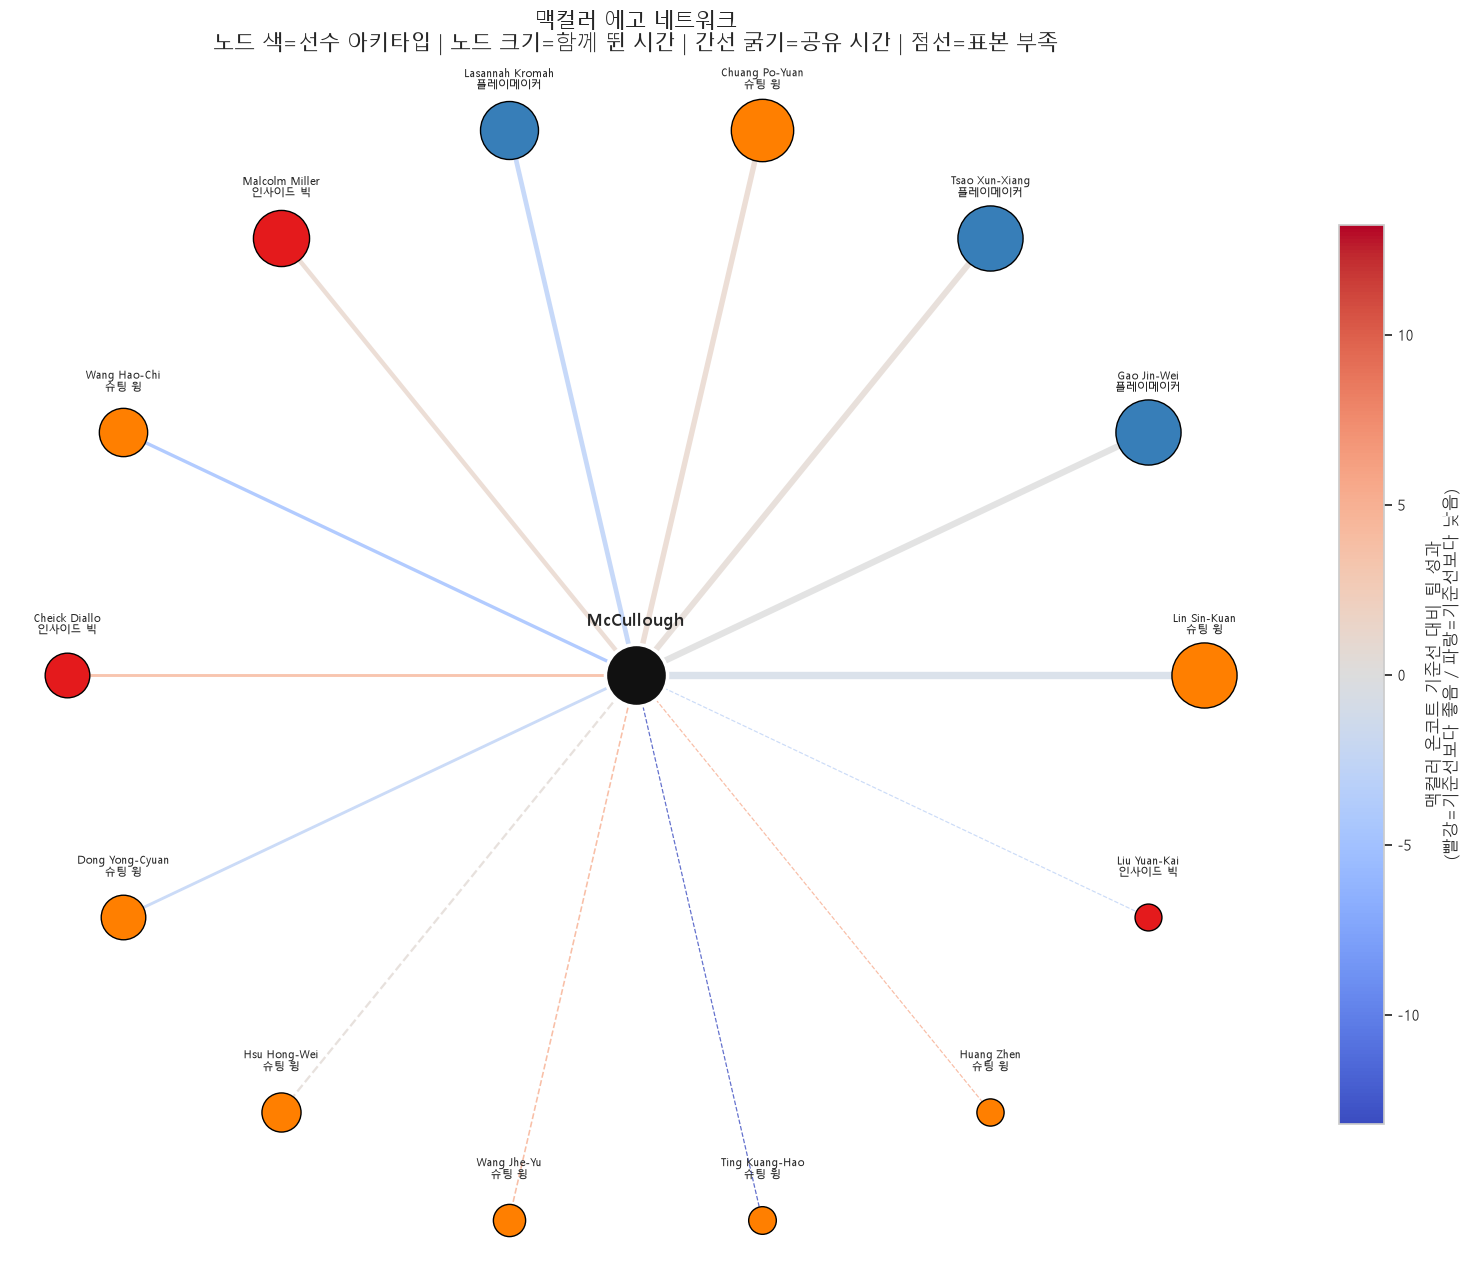

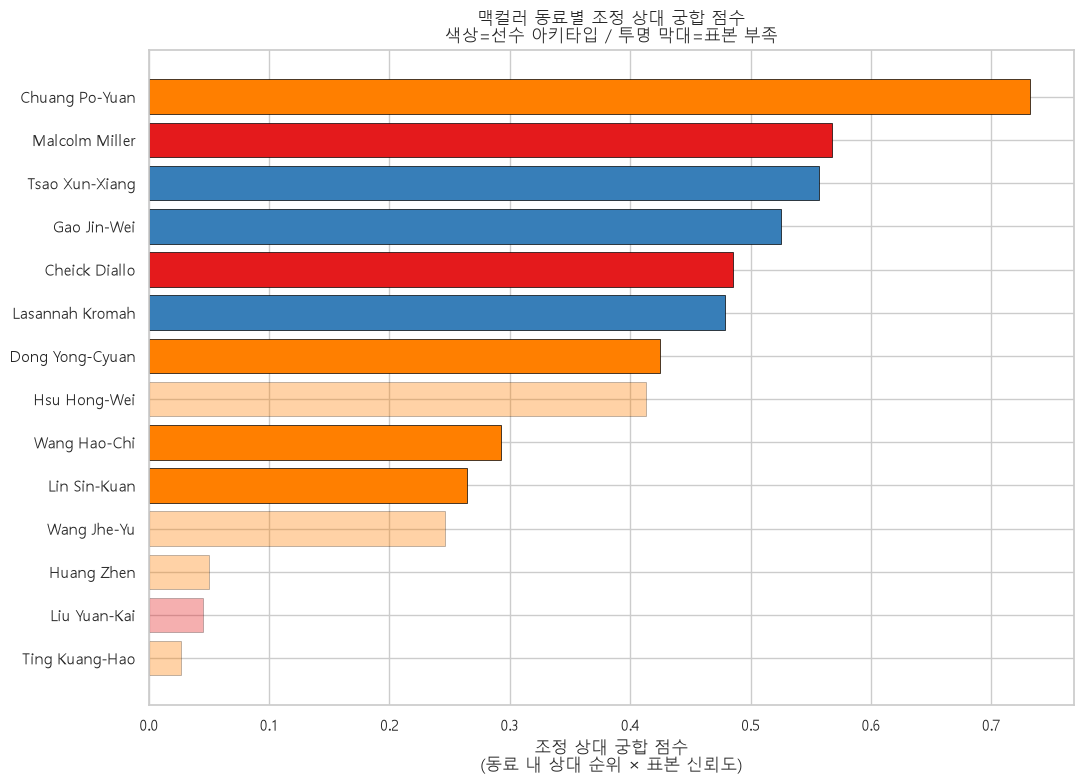

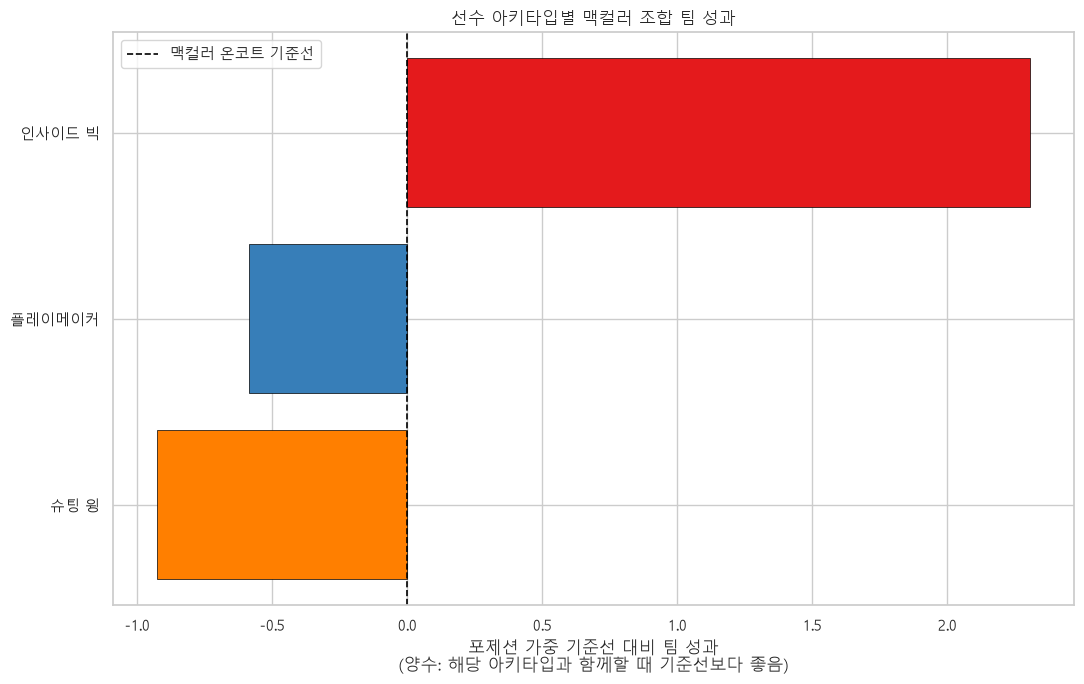

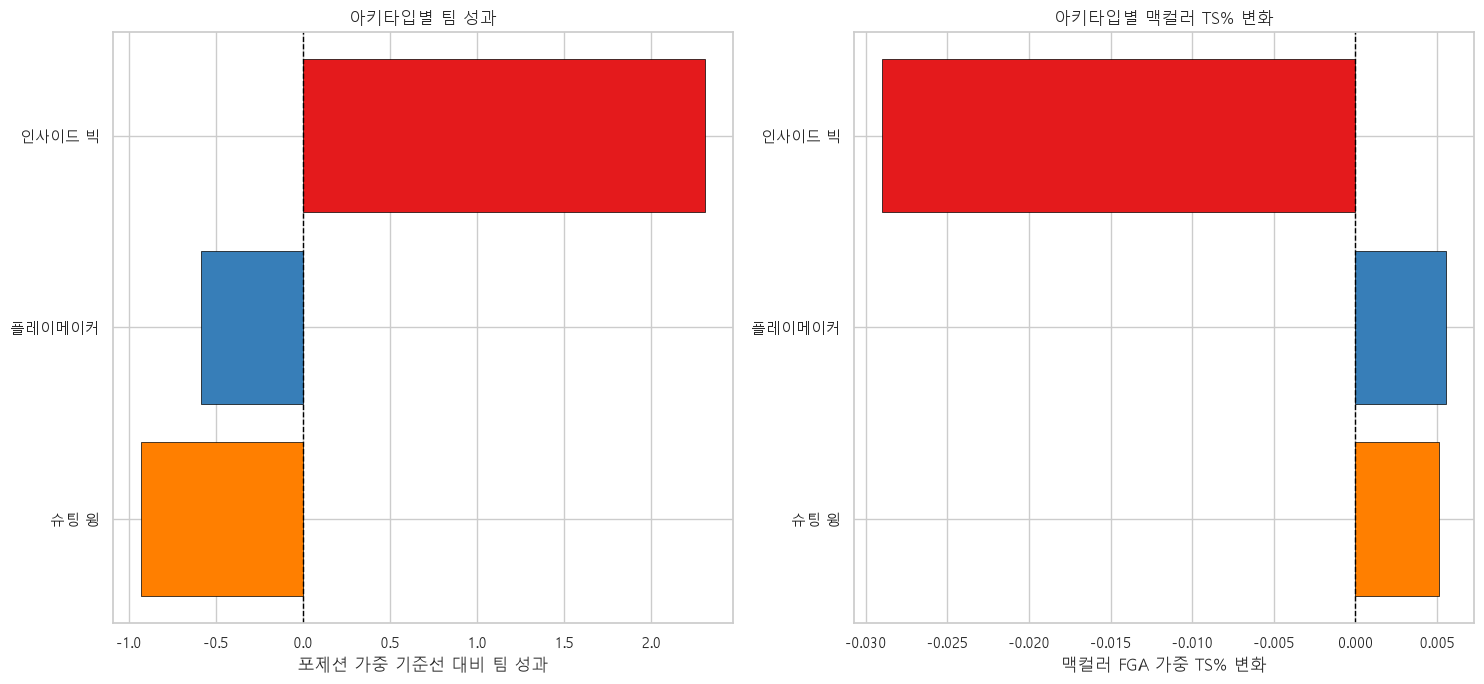

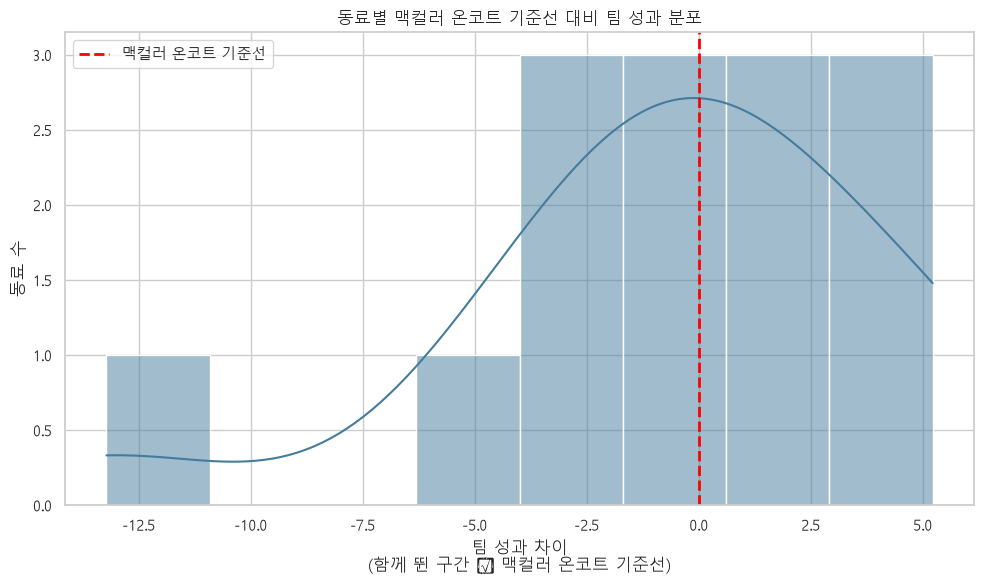

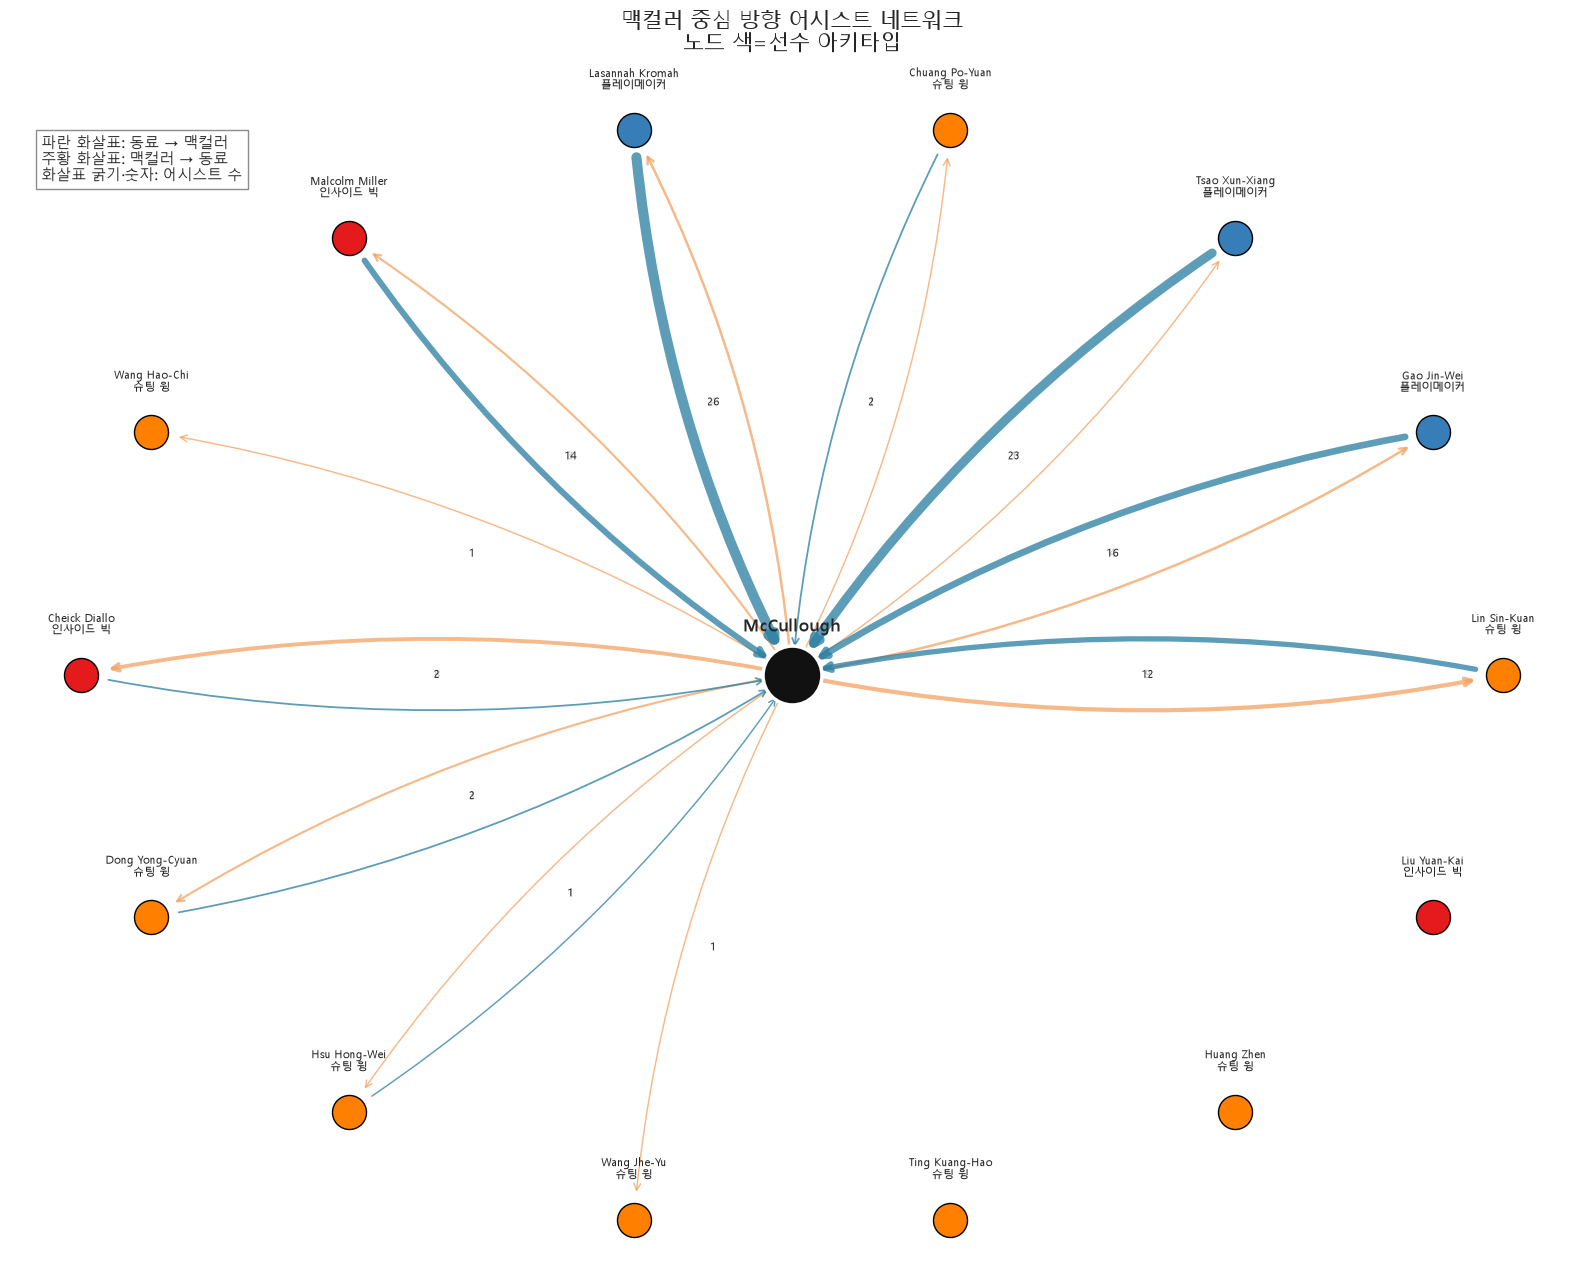

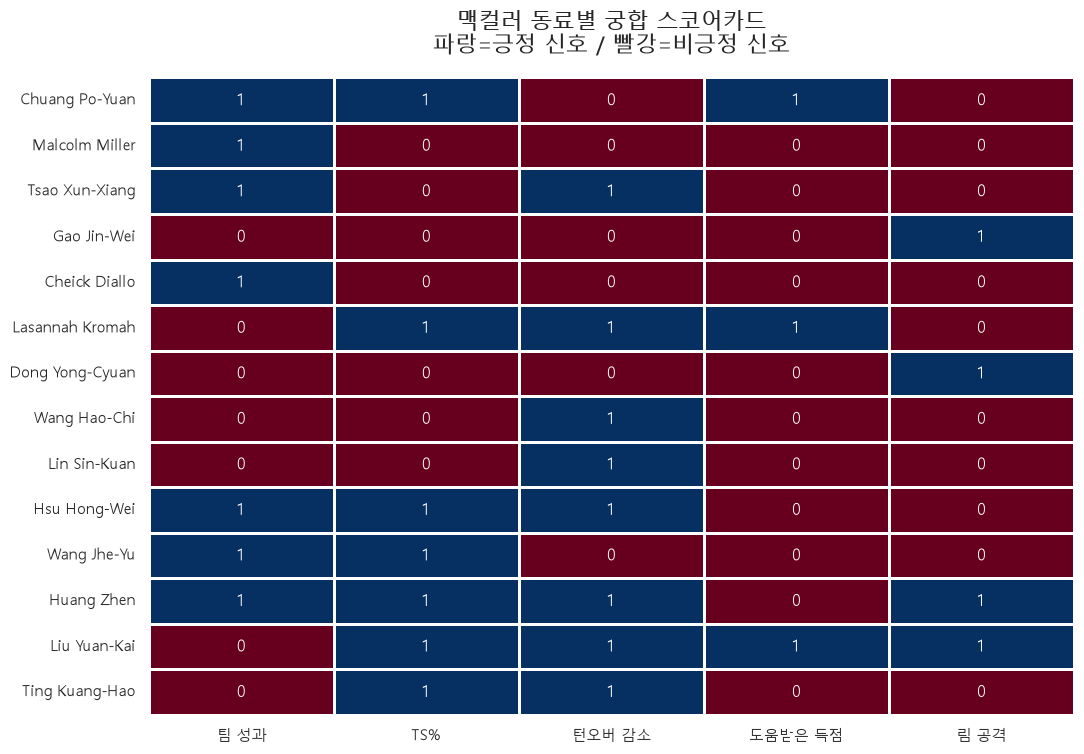

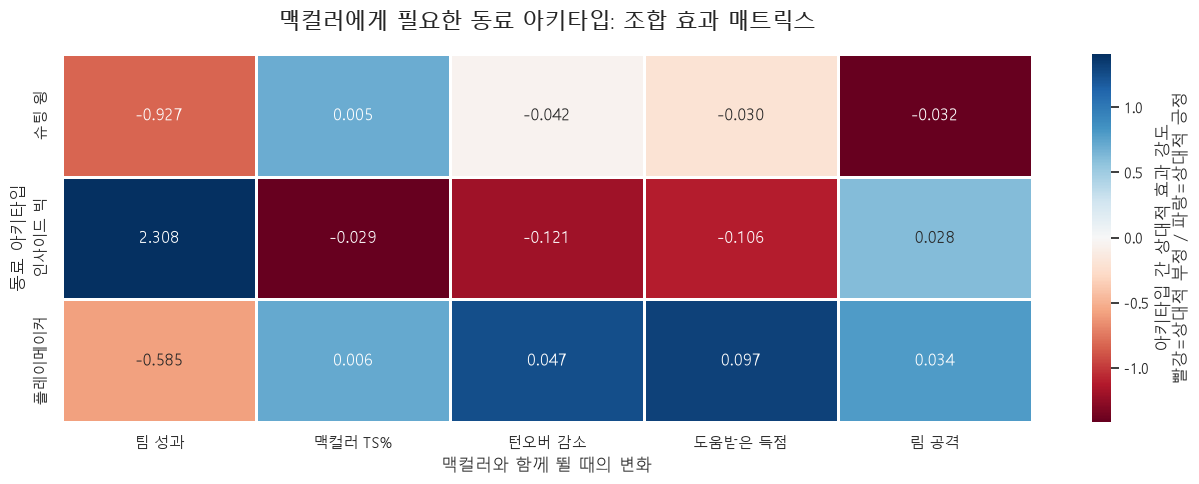


분석 완료

결과 저장 폴더:
C:\Users\livin\OneDrive\바탕 화면\foreign_1st\mcc_network_output_archetypes

[아키타입별 전체 요약]
archetype  선수수  국내선수수  외국인수     공유시간합    포제션합  팀성과_기준선대비_가중평균  맥컬러_TS변화_가중평균  조정상대궁합점수_평균  최종비교포함 제외사유
   플레이메이커  3.0    2.0   1.0 1059.4167 2063.58       -0.585183       0.005533     0.520238    True     
   인사이드 빅  3.0    1.0   2.0  398.6500  768.78        2.307775      -0.028980     0.366246    True     
     슈팅 윙  8.0    8.0   0.0 1263.1333 2457.56       -0.927400       0.005138     0.306315    True     

[최종 비교 대상 아키타입]
archetype  선수수     공유시간합    포제션합  팀성과_기준선대비_가중평균  맥컬러_TS변화_가중평균  조정상대궁합점수_평균
   플레이메이커  3.0 1059.4167 2063.58       -0.585183       0.005533     0.520238
   인사이드 빅  3.0  398.6500  768.78        2.307775      -0.028980     0.366246
     슈팅 윙  8.0 1263.1333 2457.56       -0.927400       0.005138     0.306315

[동료별 조정 상대 궁합 점수 상위 10명]
           name archetype national_type  shared_minutes  team_with_poss  team_net_vs_baseline  mcc_ts_vs_baseline  adjusted_relative

In [2]:
# ============================================================
# 맥컬러 네트워크 분석
# KBL 국내 선수 매핑용 아키타입 분류 최종 코드
#
# 선수 아키타입:
# 1. 플레이메이커
# 2. 슈팅 윙
# 3. 수비·연결형 윙
# 4. 인사이드 빅
#
# 외국인 여부는 아키타입과 별도로 national_type에 보존
#
# 필요 파일:
# - nodes-7.csv
# - edges_mcc_ego-4.csv
# - edges_assist.csv
#
# 결과 폴더:
# - mcc_network_output_archetypes
# ============================================================


# ============================================================
# 0. 라이브러리 및 한글 폰트 설정
# ============================================================

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns


# ------------------------------------------------------------
# Seaborn 테마
# ------------------------------------------------------------

sns.set_theme(
    style="whitegrid",
    font_scale=1.0
)


# ------------------------------------------------------------
# Windows 한글 폰트
# ------------------------------------------------------------

font_path = Path(
    r"C:\Windows\Fonts\malgun.ttf"
)

if font_path.exists():

    font_prop = fm.FontProperties(
        fname=str(font_path)
    )

    korean_font = font_prop.get_name()

    plt.rcParams["font.family"] = korean_font
    plt.rcParams["font.sans-serif"] = [korean_font]

else:

    plt.rcParams["font.family"] = "Malgun Gothic"
    plt.rcParams["font.sans-serif"] = ["Malgun Gothic"]

plt.rcParams["axes.unicode_minus"] = False


# ============================================================
# 1. 경로 및 분석 설정
# ============================================================

DATA_DIR = Path.cwd()

OUTPUT_DIR = (
    DATA_DIR
    / "mcc_network_output_archetypes"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

NODES_FILE = DATA_DIR / "nodes.csv"
EGO_FILE = DATA_DIR / "edges_mcc_ego.csv"
ASSIST_FILE = DATA_DIR / "edges_assist.csv"

MCC_ID = "10860"


# ------------------------------------------------------------
# 표본 기준
# ------------------------------------------------------------

MIN_SHARED_MINUTES = 80
MIN_POSSESSIONS = 200

MIN_PLAYERS_PER_ARCHETYPE = 2
MIN_TOTAL_POSS_PER_ARCHETYPE = 200


# ------------------------------------------------------------
# 긍정 신호 기준
# ------------------------------------------------------------

TEAM_EFFECT_THRESHOLD = 0.0
TS_EFFECT_THRESHOLD = 0.01
TOV_EFFECT_THRESHOLD = -0.10
ASSISTED_SHARE_THRESHOLD = 0.10
RIM_SHARE_THRESHOLD = 0.05


# ------------------------------------------------------------
# 궁합 점수 가중치
# ------------------------------------------------------------

W_TEAM = 0.40
W_TS = 0.25
W_ASSISTED = 0.20
W_RIM = 0.15


# ------------------------------------------------------------
# 아키타입 색상
# ------------------------------------------------------------

archetype_colors = {
    "플레이메이커": "#377EB8",      # 파랑
    "슈팅 윙": "#FF7F00",            # 주황
    "수비·연결형 윙": "#4DAF4A",     # 초록
    "인사이드 빅": "#E41A1C",        # 빨강
    "맥컬러": "#111111"
}


print("=" * 70)
print("맥컬러 네트워크 분석 시작")
print("분류 체계: 플레이메이커 / 슈팅 윙 / 수비·연결형 윙 / 인사이드 빅")
print(f"현재 작업 폴더: {DATA_DIR}")
print(f"결과 저장 폴더: {OUTPUT_DIR.resolve()}")
print("=" * 70)


# ============================================================
# 2. 데이터 로드 함수
# ============================================================

def load_csv(file_path):
    """
    ID 컬럼을 문자열로 고정하여 CSV 파일을 읽는다.
    """

    if not file_path.exists():

        raise FileNotFoundError(
            f"\n파일을 찾지 못했습니다: {file_path}\n\n"
            "현재 작업 폴더에 아래 파일이 있는지 확인하세요.\n"
            "- nodes-7.csv\n"
            "- edges_mcc_ego-4.csv\n"
            "- edges_assist.csv"
        )

    df = pd.read_csv(
        file_path,
        dtype={
            "player_id": str,
            "source": str,
            "target": str,
            "team_id": str
        }
    )

    for col in [
        "player_id",
        "source",
        "target",
        "team_id"
    ]:

        if col in df.columns:
            df[col] = df[col].astype(str)

    return df


# ============================================================
# 3. 데이터 로드
# ============================================================

nodes = load_csv(NODES_FILE)
ego = load_csv(EGO_FILE)
assist = load_csv(ASSIST_FILE)

print("\n[데이터 크기]")
print(f"nodes: {nodes.shape}")
print(f"edges_mcc_ego: {ego.shape}")
print(f"edges_assist: {assist.shape}")


# ============================================================
# 4. 맥컬러-동료 데이터 생성
# ============================================================

teammates = ego[
    ego["source"] == MCC_ID
].copy()

if teammates.empty:

    raise ValueError(
        "맥컬러(source='10860') 관계를 찾지 못했습니다."
    )


# ------------------------------------------------------------
# nodes 선수 스탯 결합
# ------------------------------------------------------------

node_cols = [
    "player_id",
    "player_name_english",
    "position",
    "national_identity",
    "is_imported",
    "height_cm",
    "weight_kg",
    "games",
    "minutes",
    "PTS_per36",
    "FGA_per36",
    "3PA_per36",
    "FTA_per36",
    "AST_per36",
    "REB_per36",
    "OREB_per36",
    "DREB_per36",
    "STL_per36",
    "BLK_per36",
    "TOV_per36",
    "TS_pct",
    "3P_pct",
    "3PA_rate",
    "FT_rate",
    "paint_FGA_share",
    "AST_TOV"
]

node_cols = [
    col for col in node_cols
    if col in nodes.columns
]

teammates = teammates.merge(
    nodes[node_cols],
    left_on="target",
    right_on="player_id",
    how="left",
    suffixes=("", "_node")
)


# ============================================================
# 5. 이름·포지션·국적 정보 통일
# ============================================================

# ------------------------------------------------------------
# 선수 이름
# ------------------------------------------------------------

teammates["name"] = np.nan

name_candidates = [
    "target_name",
    "player_name_english",
    "player_name_english_node",
    "target"
]

for col in name_candidates:

    if col in teammates.columns:

        teammates["name"] = (
            teammates["name"]
            .fillna(
                teammates[col].astype(str)
            )
        )

teammates["name"] = teammates["name"].fillna(
    teammates["target"].astype(str)
)


# ------------------------------------------------------------
# 포지션
# ------------------------------------------------------------

teammates["position_final"] = np.nan

position_candidates = [
    "target_position",
    "position",
    "position_node"
]

for col in position_candidates:

    if col in teammates.columns:

        teammates["position_final"] = (
            teammates["position_final"]
            .fillna(
                teammates[col].astype(str)
            )
        )

teammates["position_final"] = (
    teammates["position_final"]
    .fillna("Unknown")
)


# ------------------------------------------------------------
# 외국인 여부
# ------------------------------------------------------------

teammates["is_imported_final"] = False

imported_candidates = [
    "target_is_imported",
    "is_imported",
    "is_imported_node"
]

for col in imported_candidates:

    if col in teammates.columns:

        teammates["is_imported_final"] = (
            teammates["is_imported_final"]
            | teammates[col]
            .fillna(False)
            .astype(bool)
        )

teammates["national_type"] = np.where(
    teammates["is_imported_final"],
    "외국인",
    "국내"
)


# ============================================================
# 6. 파생 변수 생성
# ============================================================

derived_columns = {
    "team_net_diff": (
        "team_with_net_per100_shrunk",
        "team_without_net_per100_shrunk"
    ),

    "mcc_diff_TS_pct": (
        "mcc_with_TS_pct",
        "mcc_without_TS_pct"
    ),

    "mcc_diff_TOV_per36": (
        "mcc_with_TOV_per36",
        "mcc_without_TOV_per36"
    ),

    "mcc_diff_assisted_share": (
        "mcc_with_assisted_share",
        "mcc_without_assisted_share"
    ),

    "mcc_diff_rim_share": (
        "mcc_with_rim_share",
        "mcc_without_rim_share"
    ),

    "mcc_diff_usage_share": (
        "mcc_with_usage_share",
        "mcc_without_usage_share"
    )
}

for new_col, (
    with_col,
    without_col
) in derived_columns.items():

    if new_col not in teammates.columns:

        if (
            with_col in teammates.columns
            and without_col in teammates.columns
        ):

            teammates[new_col] = (
                teammates[with_col]
                - teammates[without_col]
            )

        else:

            teammates[new_col] = np.nan


# ------------------------------------------------------------
# 맥컬러 온코트 기준선
# ------------------------------------------------------------

mcc_row = nodes[
    nodes["player_id"] == MCC_ID
]

if mcc_row.empty:

    raise ValueError(
        "nodes-7.csv에서 맥컬러 ID 10860을 찾지 못했습니다."
    )

mcc_node = mcc_row.iloc[0]

baseline_net = mcc_node.get(
    "on_net_per100_shrunk",
    np.nan
)

baseline_ts = mcc_node.get(
    "TS_pct",
    np.nan
)

baseline_tov = mcc_node.get(
    "TOV_per36",
    np.nan
)

teammates["team_net_vs_baseline"] = (
    teammates["team_with_net_per100_shrunk"]
    - baseline_net
)

teammates["mcc_ts_vs_baseline"] = (
    teammates["mcc_with_TS_pct"]
    - baseline_ts
)

teammates["mcc_tov_vs_baseline"] = (
    teammates["mcc_with_TOV_per36"]
    - baseline_tov
)


# ------------------------------------------------------------
# 표본 부족 여부
# ------------------------------------------------------------

teammates["usable_for_main"] = (
    (
        teammates["shared_minutes"]
        >= MIN_SHARED_MINUTES
    )
    & (
        teammates["team_with_poss"]
        >= MIN_POSSESSIONS
    )
)

teammates["small_sample"] = (
    ~teammates["usable_for_main"]
)


# ============================================================
# 7. KBL 매핑용 선수 아키타입 분류
# ============================================================

def classify_kbl_archetype(row):
    """
    KBL 국내 선수 매핑을 위한 역할 아키타입 분류.

    유형:
    1. 플레이메이커
       - 높은 어시스트 및 공격 조립 능력

    2. 슈팅 윙
       - 3&D 후보와 퓨어 슈터를 통합
       - 외곽 공간 제공 중심

    3. 수비·연결형 윙
       - 낮은 볼 점유 기반의 수비, 리바운드, 연결 기여

    4. 인사이드 빅
       - 리바운드, 블록, 페인트 공격, 림 보호

    외국인 여부는 유형에서 제거하지 않고
    national_type으로 별도 기록한다.
    """

    position = str(
        row.get("position_final", "")
    )

    height = pd.to_numeric(
        row.get("height_cm", np.nan),
        errors="coerce"
    )

    ast = pd.to_numeric(
        row.get("AST_per36", np.nan),
        errors="coerce"
    )

    ast_tov = pd.to_numeric(
        row.get("AST_TOV", np.nan),
        errors="coerce"
    )

    three_rate = pd.to_numeric(
        row.get("3PA_rate", np.nan),
        errors="coerce"
    )

    three_pa = pd.to_numeric(
        row.get("3PA_per36", np.nan),
        errors="coerce"
    )

    stl = pd.to_numeric(
        row.get("STL_per36", np.nan),
        errors="coerce"
    )

    blk = pd.to_numeric(
        row.get("BLK_per36", np.nan),
        errors="coerce"
    )

    reb = pd.to_numeric(
        row.get("REB_per36", np.nan),
        errors="coerce"
    )

    paint_share = pd.to_numeric(
        row.get("paint_FGA_share", np.nan),
        errors="coerce"
    )

    tov = pd.to_numeric(
        row.get("TOV_per36", np.nan),
        errors="coerce"
    )

    # --------------------------------------------------------
    # 1. 플레이메이커
    # 높은 어시스트 + 최소한의 볼 관리 능력
    # --------------------------------------------------------

    if (
        pd.notna(ast)
        and ast >= 4.0
        and (
            pd.isna(ast_tov)
            or ast_tov >= 1.3
        )
    ):
        return "플레이메이커"

    # --------------------------------------------------------
    # 2. 인사이드 빅
    # 신장·리바운드·블록·페인트 공격 중심
    # --------------------------------------------------------

    if (
        (
            pd.notna(height)
            and height >= 198
        )
        and (
            (
                pd.notna(reb)
                and reb >= 8.0
            )
            or (
                pd.notna(blk)
                and blk >= 1.0
            )
            or (
                pd.notna(paint_share)
                and paint_share >= 0.55
            )
            or (
                "Center" in position
            )
        )
    ):
        return "인사이드 빅"

    # --------------------------------------------------------
    # 3. 슈팅 윙
    # 높은 외곽 시도 비중 또는 외곽 시도량
    # 3&D 후보와 퓨어 슈터를 통합한 유형
    # --------------------------------------------------------

    if (
        (
            pd.notna(three_rate)
            and three_rate >= 0.35
        )
        or (
            pd.notna(three_pa)
            and three_pa >= 4.0
        )
    ):
        return "슈팅 윙"

    # --------------------------------------------------------
    # 4. 수비·연결형 윙
    # 스틸·리바운드·낮은 턴오버 등을 통한
    # 비득점 보완 역할
    # --------------------------------------------------------

    if (
        (
            pd.notna(stl)
            and stl >= 1.0
        )
        or (
            pd.notna(reb)
            and reb >= 5.0
        )
        or (
            pd.notna(tov)
            and tov <= 2.0
        )
    ):
        return "수비·연결형 윙"

    # 명확한 분류가 어려운 선수는
    # 수비·연결형 윙으로 보수적으로 배정
    return "수비·연결형 윙"


teammates["archetype"] = teammates.apply(
    classify_kbl_archetype,
    axis=1
)


print("\n[아키타입별 선수 수]")
print(
    teammates["archetype"]
    .value_counts()
)

print("\n[아키타입 × 국내/외국인]")
print(
    pd.crosstab(
        teammates["archetype"],
        teammates["national_type"]
    )
)

print("\n[선수별 아키타입 분류]")

archetype_check_cols = [
    "name",
    "position_final",
    "national_type",
    "archetype",
    "height_cm",
    "AST_per36",
    "AST_TOV",
    "3PA_per36",
    "3PA_rate",
    "STL_per36",
    "BLK_per36",
    "REB_per36",
    "paint_FGA_share"
]

print(
    teammates[
        [
            col for col in archetype_check_cols
            if col in teammates.columns
        ]
    ]
    .sort_values(
        ["archetype", "name"]
    )
    .to_string(index=False)
)


# ============================================================
# 8. 상대 궁합 점수 계산
# ============================================================

def percentile_rank(series):
    """
    값이 높을수록 1에 가까운 백분위 순위
    """

    return series.rank(
        pct=True,
        ascending=True
    )


teammates["rank_team_effect"] = percentile_rank(
    teammates["team_net_diff"]
)

teammates["rank_ts_effect"] = percentile_rank(
    teammates["mcc_diff_TS_pct"]
)

teammates["rank_assisted_effect"] = percentile_rank(
    teammates["mcc_diff_assisted_share"]
)

teammates["rank_rim_effect"] = percentile_rank(
    teammates["mcc_diff_rim_share"]
)

teammates["relative_fit_score"] = (
    W_TEAM * teammates["rank_team_effect"]
    + W_TS * teammates["rank_ts_effect"]
    + W_ASSISTED * teammates["rank_assisted_effect"]
    + W_RIM * teammates["rank_rim_effect"]
)

teammates["reliability"] = np.minimum(
    1,
    teammates["team_with_poss"]
    / MIN_POSSESSIONS
)

teammates["adjusted_relative_fit_score"] = (
    teammates["relative_fit_score"]
    * teammates["reliability"]
)


# ============================================================
# 9. 긍정 신호 스코어카드
# ============================================================

teammates["signal_team"] = (
    teammates["team_net_vs_baseline"]
    > TEAM_EFFECT_THRESHOLD
)

teammates["signal_ts"] = (
    teammates["mcc_ts_vs_baseline"]
    >= TS_EFFECT_THRESHOLD
)

teammates["signal_tov"] = (
    teammates["mcc_tov_vs_baseline"]
    <= TOV_EFFECT_THRESHOLD
)

teammates["signal_assisted"] = (
    teammates["mcc_diff_assisted_share"]
    >= ASSISTED_SHARE_THRESHOLD
)

teammates["signal_rim"] = (
    teammates["mcc_diff_rim_share"]
    >= RIM_SHARE_THRESHOLD
)

signal_cols = [
    "signal_team",
    "signal_ts",
    "signal_tov",
    "signal_assisted",
    "signal_rim"
]

teammates["positive_signal_count"] = (
    teammates[signal_cols]
    .fillna(False)
    .astype(int)
    .sum(axis=1)
)

teammates["positive_signal_ratio"] = (
    teammates["positive_signal_count"]
    / len(signal_cols)
)


def classify_synergy(row):

    count = row["positive_signal_count"]

    if count >= 4:
        return "강한 궁합"

    if count == 3:
        return "궁합 좋음"

    if count == 2:
        return "신호 엇갈림"

    return "궁합 약함"


teammates["synergy_class"] = teammates.apply(
    classify_synergy,
    axis=1
)


# ============================================================
# 10. 어시스트 관계 결합
# ============================================================

assist_internal = assist[
    assist["coverage"]
    .eq("leopards_all_games")
].copy()


# 동료 → 맥컬러
to_mcc = (
    assist_internal[
        (
            assist_internal["target"]
            == MCC_ID
        )
        & (
            assist_internal["source"]
            .isin(teammates["target"])
        )
    ]
    .groupby(
        "source",
        as_index=False
    )
    .agg(
        to_mcc_assists=(
            "assists",
            "sum"
        ),
        to_mcc_pts_created=(
            "pts_created",
            "sum"
        ),
        to_mcc_per36=(
            "assists_per36_shared",
            "mean"
        )
    )
    .rename(
        columns={
            "source": "target"
        }
    )
)


# 맥컬러 → 동료
from_mcc = (
    assist_internal[
        (
            assist_internal["source"]
            == MCC_ID
        )
        & (
            assist_internal["target"]
            .isin(teammates["target"])
        )
    ]
    .groupby(
        "target",
        as_index=False
    )
    .agg(
        from_mcc_assists=(
            "assists",
            "sum"
        ),
        from_mcc_pts_created=(
            "pts_created",
            "sum"
        ),
        from_mcc_per36=(
            "assists_per36_shared",
            "mean"
        )
    )
)

teammates = teammates.merge(
    to_mcc,
    on="target",
    how="left"
)

teammates = teammates.merge(
    from_mcc,
    on="target",
    how="left"
)

assist_fill_cols = [
    "to_mcc_assists",
    "to_mcc_pts_created",
    "to_mcc_per36",
    "from_mcc_assists",
    "from_mcc_pts_created",
    "from_mcc_per36"
]

for col in assist_fill_cols:
    teammates[col] = teammates[col].fillna(0)

teammates["total_assist_connection"] = (
    teammates["to_mcc_assists"]
    + teammates["from_mcc_assists"]
)

teammates["assist_reciprocity"] = np.where(
    teammates[
        [
            "to_mcc_assists",
            "from_mcc_assists"
        ]
    ].max(axis=1) > 0,

    teammates[
        [
            "to_mcc_assists",
            "from_mcc_assists"
        ]
    ].min(axis=1)
    /
    teammates[
        [
            "to_mcc_assists",
            "from_mcc_assists"
        ]
    ].max(axis=1),

    0
)


# ============================================================
# 11. 가중 평균 함수
# ============================================================

def weighted_mean(
    group,
    value_col,
    weight_col
):
    """
    포제션 또는 FGA 기준 가중 평균
    """

    values = pd.to_numeric(
        group[value_col],
        errors="coerce"
    )

    weights = pd.to_numeric(
        group[weight_col],
        errors="coerce"
    )

    valid = (
        values.notna()
        & weights.notna()
        & (weights > 0)
    )

    if valid.sum() == 0:
        return np.nan

    return np.average(
        values.loc[valid],
        weights=weights.loc[valid]
    )


def weighted_share(
    group,
    bool_col,
    weight_col
):
    """
    True/False 신호의 가중 비율
    """

    values = (
        group[bool_col]
        .fillna(False)
        .astype(float)
    )

    weights = pd.to_numeric(
        group[weight_col],
        errors="coerce"
    )

    valid = (
        values.notna()
        & weights.notna()
        & (weights > 0)
    )

    if valid.sum() == 0:
        return np.nan

    return np.average(
        values.loc[valid],
        weights=weights.loc[valid]
    )


# ============================================================
# 12. 아키타입별 요약
# ============================================================

def summarize_archetype(group):

    return pd.Series({

        "선수수": group["target"].nunique(),

        "국내선수수": (
            group["national_type"]
            == "국내"
        ).sum(),

        "외국인수": (
            group["national_type"]
            == "외국인"
        ).sum(),

        "공유시간합": group[
            "shared_minutes"
        ].sum(),

        "포제션합": group[
            "team_with_poss"
        ].sum(),

        "팀성과_기준선대비_가중평균": weighted_mean(
            group,
            "team_net_vs_baseline",
            "team_with_poss"
        ),

        "팀성과_함께대비따로_가중평균": weighted_mean(
            group,
            "team_net_diff",
            "team_with_poss"
        ),

        "맥컬러_TS변화_가중평균": weighted_mean(
            group,
            "mcc_ts_vs_baseline",
            "mcc_with_FGA"
        ),

        "맥컬러_TOV변화_가중평균": weighted_mean(
            group,
            "mcc_tov_vs_baseline",
            "mcc_with_FGA"
        ),

        "맥컬러_assisted변화_가중평균": weighted_mean(
            group,
            "mcc_diff_assisted_share",
            "mcc_with_FGA"
        ),

        "맥컬러_rim변화_가중평균": weighted_mean(
            group,
            "mcc_diff_rim_share",
            "mcc_with_FGA"
        ),

        "상대궁합점수_평균": group[
            "relative_fit_score"
        ].mean(),

        "조정상대궁합점수_평균": group[
            "adjusted_relative_fit_score"
        ].mean(),

        "긍정신호수_평균": group[
            "positive_signal_count"
        ].mean(),

        "팀성과_긍정비율": weighted_share(
            group,
            "signal_team",
            "team_with_poss"
        ),

        "TS_긍정비율": weighted_share(
            group,
            "signal_ts",
            "mcc_with_FGA"
        ),

        "TOV_긍정비율": weighted_share(
            group,
            "signal_tov",
            "mcc_with_FGA"
        ),

        "assisted_긍정비율": weighted_share(
            group,
            "signal_assisted",
            "mcc_with_FGA"
        ),

        "림공격_긍정비율": weighted_share(
            group,
            "signal_rim",
            "mcc_with_FGA"
        ),

        "맥컬러에게_어시스트36분당_가중평균": weighted_mean(
            group,
            "to_mcc_per36",
            "shared_minutes"
        ),

        "맥컬러에게_총어시스트": group[
            "to_mcc_assists"
        ].sum()
    })


archetype_summary_all = (
    teammates
    .groupby(
        "archetype",
        dropna=False
    )
    .apply(summarize_archetype)
    .reset_index()
)

archetype_summary_all["최종비교포함"] = (
    (
        archetype_summary_all["선수수"]
        >= MIN_PLAYERS_PER_ARCHETYPE
    )
    & (
        archetype_summary_all["포제션합"]
        >= MIN_TOTAL_POSS_PER_ARCHETYPE
    )
)

archetype_summary_all["제외사유"] = np.where(
    archetype_summary_all["최종비교포함"],
    "",
    "선수 수 또는 포제션 표본 부족"
)

archetype_summary_main = (
    archetype_summary_all[
        archetype_summary_all["최종비교포함"]
    ]
    .copy()
    .sort_values(
        "조정상대궁합점수_평균",
        ascending=False
    )
)


# ============================================================
# 13. 동료별 궁합 스코어카드 테이블
# ============================================================

scorecard_cols = [
    "target",
    "name",
    "position_final",
    "national_type",
    "archetype",

    "shared_minutes",
    "team_with_poss",
    "usable_for_main",
    "small_sample",

    "team_with_net_per100_shrunk",
    "team_net_vs_baseline",
    "team_net_diff",

    "mcc_with_TS_pct",
    "mcc_ts_vs_baseline",
    "mcc_diff_TS_pct",

    "mcc_tov_vs_baseline",
    "mcc_diff_TOV_per36",

    "mcc_diff_assisted_share",
    "mcc_diff_rim_share",

    "to_mcc_assists",
    "to_mcc_per36",
    "from_mcc_assists",
    "from_mcc_per36",
    "assist_reciprocity",

    "relative_fit_score",
    "reliability",
    "adjusted_relative_fit_score",

    "signal_team",
    "signal_ts",
    "signal_tov",
    "signal_assisted",
    "signal_rim",

    "positive_signal_count",
    "positive_signal_ratio",
    "synergy_class"
]

scorecard_cols = [
    col for col in scorecard_cols
    if col in teammates.columns
]

scorecard = teammates[
    scorecard_cols
].copy()

scorecard = scorecard.sort_values(
    [
        "usable_for_main",
        "adjusted_relative_fit_score"
    ],
    ascending=[
        False,
        False
    ]
)


# ============================================================
# 14. 맥컬러 에고 네트워크 생성
# ============================================================

G = nx.Graph()

G.add_node(
    MCC_ID,
    name="Chris McCullough",
    archetype="맥컬러",
    national_type="외국인",
    node_color=archetype_colors["맥컬러"],
    node_size=2000,
    small_sample=False
)

for _, row in teammates.iterrows():

    player_id = str(row["target"])

    archetype = row.get(
        "archetype",
        "수비·연결형 윙"
    )

    shared_minutes = pd.to_numeric(
        row.get("shared_minutes", 0),
        errors="coerce"
    )

    if pd.isna(shared_minutes):
        shared_minutes = 0

    G.add_node(
        player_id,
        name=row.get("name", player_id),
        archetype=archetype,
        national_type=row.get(
            "national_type",
            "국내"
        ),
        node_color=archetype_colors.get(
            archetype,
            "#999999"
        ),
        node_size=350 + 5 * shared_minutes,
        small_sample=bool(
            row.get("small_sample", False)
        )
    )

    G.add_edge(
        MCC_ID,
        player_id,
        shared_minutes=float(shared_minutes),
        team_net_diff=row.get(
            "team_net_diff",
            np.nan
        ),
        team_vs_baseline=row.get(
            "team_net_vs_baseline",
            np.nan
        ),
        adjusted_relative_fit=row.get(
            "adjusted_relative_fit_score",
            np.nan
        ),
        team_poss=row.get(
            "team_with_poss",
            np.nan
        ),
        small_sample=bool(
            row.get("small_sample", False)
        )
    )

nx.write_gexf(
    G,
    str(
        OUTPUT_DIR
        / "01_mcc_ego_network_archetypes.gexf"
    )
)


# ============================================================
# 15. 맥컬러 에고 네트워크 시각화
# ============================================================

fig, ax = plt.subplots(
    figsize=(16, 13)
)

ego_pos = {
    MCC_ID: np.array([0.0, 0.0])
}

ego_nodes = [
    node for node in G.nodes
    if node != MCC_ID
]

angles = np.linspace(
    0,
    2 * np.pi,
    len(ego_nodes),
    endpoint=False
)

radius = 4.0

for node, angle in zip(
    ego_nodes,
    angles
):

    ego_pos[node] = np.array([
        radius * np.cos(angle),
        radius * np.sin(angle)
    ])

edge_values = np.array([
    G[MCC_ID][node].get(
        "team_vs_baseline",
        0
    )
    for node in ego_nodes
])

vmax = max(
    np.nanmax(
        np.abs(edge_values)
    ),
    1
)

edge_norm = plt.Normalize(
    -vmax,
    vmax
)

edge_cmap = plt.cm.coolwarm


# 간선
for node in ego_nodes:

    edge_data = G[MCC_ID][node]

    edge_color = edge_cmap(
        edge_norm(
            edge_data.get(
                "team_vs_baseline",
                0
            )
        )
    )

    edge_width = (
        0.8
        + 4.5
        * edge_data.get(
            "shared_minutes",
            0
        )
        / max(
            teammates["shared_minutes"].max(),
            1
        )
    )

    edge_style = (
        "--"
        if edge_data.get(
            "small_sample",
            False
        )
        else "-"
    )

    ax.plot(
        [
            ego_pos[MCC_ID][0],
            ego_pos[node][0]
        ],
        [
            ego_pos[MCC_ID][1],
            ego_pos[node][1]
        ],
        color=edge_color,
        linewidth=edge_width,
        linestyle=edge_style,
        alpha=0.80,
        zorder=1
    )


# 노드
for node in G.nodes:

    attrs = G.nodes[node]

    ax.scatter(
        ego_pos[node][0],
        ego_pos[node][1],
        s=min(
            attrs.get(
                "node_size",
                500
            ),
            2200
        ),
        c=attrs.get(
            "node_color",
            "#999999"
        ),
        edgecolors=(
            "white"
            if node == MCC_ID
            else "black"
        ),
        linewidths=(
            2.5
            if node == MCC_ID
            else 1.0
        ),
        zorder=3
    )


# 라벨
for node in G.nodes:

    attrs = G.nodes[node]

    if node == MCC_ID:

        label = "McCullough"
        font_size = 12
        font_weight = "bold"
        y_offset = 0.32

    else:

        label = (
            f"{attrs.get('name', node)}\n"
            f"{attrs.get('archetype', '')}"
        )

        font_size = 8
        font_weight = "normal"
        y_offset = 0.28

    ax.text(
        ego_pos[node][0],
        ego_pos[node][1] + y_offset,
        label,
        ha="center",
        va="bottom",
        fontsize=font_size,
        fontweight=font_weight,
        zorder=4
    )


sm = plt.cm.ScalarMappable(
    cmap=edge_cmap,
    norm=edge_norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    shrink=0.75
)

cbar.set_label(
    "맥컬러 온코트 기준선 대비 팀 성과\n"
    "(빨강=기준선보다 좋음 / 파랑=기준선보다 낮음)"
)

ax.set_title(
    "맥컬러 에고 네트워크\n"
    "노드 색=선수 아키타입 | "
    "노드 크기=함께 뛴 시간 | "
    "간선 굵기=공유 시간 | "
    "점선=표본 부족",
    fontsize=15,
    pad=18
)

ax.axis("off")

plt.tight_layout()

plt.savefig(
    str(
        OUTPUT_DIR
        / "02_mcc_ego_network_archetypes.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 16. 동료별 조정 상대 궁합 점수 그래프
# ============================================================

plot_score = teammates.sort_values(
    "adjusted_relative_fit_score",
    ascending=True
).copy()

fig, ax = plt.subplots(
    figsize=(11, 8)
)

bar_colors = [
    archetype_colors.get(
        archetype,
        "#999999"
    )
    for archetype in plot_score["archetype"]
]

bars = ax.barh(
    plot_score["name"],
    plot_score[
        "adjusted_relative_fit_score"
    ],
    color=bar_colors,
    edgecolor="black",
    linewidth=0.5
)

for bar, small_sample in zip(
    bars,
    plot_score["small_sample"]
):

    if small_sample:
        bar.set_alpha(0.35)

ax.set_xlabel(
    "조정 상대 궁합 점수\n"
    "(동료 내 상대 순위 × 표본 신뢰도)"
)

ax.set_ylabel("")

ax.set_title(
    "맥컬러 동료별 조정 상대 궁합 점수\n"
    "색상=선수 아키타입 / 투명 막대=표본 부족"
)

plt.tight_layout()

plt.savefig(
    str(
        OUTPUT_DIR
        / "03_teammate_adjusted_relative_fit_archetypes.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 17. 아키타입별 팀 성과 그래프
# ============================================================

plot_type = archetype_summary_main.copy()

if not plot_type.empty:

    plot_type = plot_type.sort_values(
        "팀성과_기준선대비_가중평균",
        ascending=True
    )

    fig, ax = plt.subplots(
        figsize=(11, 7)
    )

    colors = [
        archetype_colors.get(
            archetype,
            "#999999"
        )
        for archetype in plot_type["archetype"]
    ]

    ax.barh(
        plot_type["archetype"],
        plot_type[
            "팀성과_기준선대비_가중평균"
        ],
        color=colors,
        edgecolor="black",
        linewidth=0.5
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="맥컬러 온코트 기준선"
    )

    ax.set_xlabel(
        "포제션 가중 기준선 대비 팀 성과\n"
        "(양수: 해당 아키타입과 함께할 때 기준선보다 좋음)"
    )

    ax.set_ylabel("")

    ax.set_title(
        "선수 아키타입별 맥컬러 조합 팀 성과"
    )

    ax.legend()

    plt.tight_layout()

    plt.savefig(
        str(
            OUTPUT_DIR
            / "04_archetype_weighted_team_effect.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# ============================================================
# 18. 아키타입별 팀 성과와 TS 변화 비교
# ============================================================

if not plot_type.empty:

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(15, 7)
    )

    archetype_color_list = [
        archetype_colors.get(
            archetype,
            "#999999"
        )
        for archetype in plot_type["archetype"]
    ]

    axes[0].barh(
        plot_type["archetype"],
        plot_type[
            "팀성과_기준선대비_가중평균"
        ],
        color=archetype_color_list,
        edgecolor="black",
        linewidth=0.5
    )

    axes[0].axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    axes[0].set_title(
        "아키타입별 팀 성과"
    )

    axes[0].set_xlabel(
        "포제션 가중 기준선 대비 팀 성과"
    )

    axes[0].set_ylabel("")

    axes[1].barh(
        plot_type["archetype"],
        plot_type[
            "맥컬러_TS변화_가중평균"
        ],
        color=archetype_color_list,
        edgecolor="black",
        linewidth=0.5
    )

    axes[1].axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    axes[1].set_title(
        "아키타입별 맥컬러 TS% 변화"
    )

    axes[1].set_xlabel(
        "맥컬러 FGA 가중 TS% 변화"
    )

    axes[1].set_ylabel("")

    plt.tight_layout()

    plt.savefig(
        str(
            OUTPUT_DIR
            / "05_archetype_team_ts_comparison.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# ============================================================
# 19. 팀 성과 분포
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

sns.histplot(
    data=teammates,
    x="team_net_vs_baseline",
    bins=8,
    kde=True,
    ax=ax,
    color="#457B9D"
)

ax.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="맥컬러 온코트 기준선"
)

ax.set_title(
    "동료별 맥컬러 온코트 기준선 대비 팀 성과 분포"
)

ax.set_xlabel(
    "팀 성과 차이\n"
    "(함께 뛴 구간 − 맥컬러 온코트 기준선)"
)

ax.set_ylabel("동료 수")

ax.legend()

plt.tight_layout()

plt.savefig(
    str(
        OUTPUT_DIR
        / "06_team_effect_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 20. 방향 어시스트 네트워크
# ============================================================

A = nx.DiGraph()

A.add_node(
    MCC_ID,
    name="Chris McCullough",
    archetype="맥컬러",
    national_type="외국인",
    node_color=archetype_colors["맥컬러"],
    node_size=2000
)

for _, row in teammates.iterrows():

    player_id = str(row["target"])

    archetype = row.get(
        "archetype",
        "수비·연결형 윙"
    )

    A.add_node(
        player_id,
        name=row.get(
            "name",
            player_id
        ),
        archetype=archetype,
        national_type=row.get(
            "national_type",
            "국내"
        ),
        node_color=archetype_colors.get(
            archetype,
            "#999999"
        ),
        node_size=600
    )

    to_mcc = pd.to_numeric(
        row.get(
            "to_mcc_assists",
            0
        ),
        errors="coerce"
    )

    from_mcc = pd.to_numeric(
        row.get(
            "from_mcc_assists",
            0
        ),
        errors="coerce"
    )

    if pd.isna(to_mcc):
        to_mcc = 0

    if pd.isna(from_mcc):
        from_mcc = 0

    if to_mcc > 0:

        A.add_edge(
            player_id,
            MCC_ID,
            assists=float(to_mcc),
            direction="to_mcc"
        )

    if from_mcc > 0:

        A.add_edge(
            MCC_ID,
            player_id,
            assists=float(from_mcc),
            direction="from_mcc"
        )

nx.write_gexf(
    A,
    str(
        OUTPUT_DIR
        / "07_mcc_assist_network_archetypes.gexf"
    )
)


# ============================================================
# 21. 방향 어시스트 네트워크 시각화
# ============================================================

fig, ax = plt.subplots(
    figsize=(16, 13)
)

assist_pos = {
    MCC_ID: np.array([0.0, 0.0])
}

assist_nodes = [
    node for node in A.nodes
    if node != MCC_ID
]

angles = np.linspace(
    0,
    2 * np.pi,
    len(assist_nodes),
    endpoint=False
)

radius = 4.0

for node, angle in zip(
    assist_nodes,
    angles
):

    assist_pos[node] = np.array([
        radius * np.cos(angle),
        radius * np.sin(angle)
    ])


for source, target, edge_data in A.edges(
    data=True
):

    if edge_data.get(
        "direction"
    ) == "to_mcc":

        edge_color = "#277DA1"

    else:

        edge_color = "#F4A261"

    assists = edge_data.get(
        "assists",
        0
    )

    edge_width = (
        0.8
        + 0.25 * assists
    )

    ax.annotate(
        "",
        xy=assist_pos[target],
        xytext=assist_pos[source],
        arrowprops=dict(
            arrowstyle="->",
            color=edge_color,
            linewidth=edge_width,
            alpha=0.75,
            shrinkA=20,
            shrinkB=20,
            connectionstyle="arc3,rad=0.10"
        )
    )

    mid_x = (
        assist_pos[source][0]
        + assist_pos[target][0]
    ) / 2

    mid_y = (
        assist_pos[source][1]
        + assist_pos[target][1]
    ) / 2

    ax.text(
        mid_x,
        mid_y,
        str(int(assists)),
        fontsize=8,
        ha="center",
        va="center",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.70,
            pad=1
        )
    )


for node in A.nodes:

    attrs = A.nodes[node]

    if node == MCC_ID:

        color = "#111111"
        node_size = 1800
        edge_color = "white"
        edge_width = 2.5

    else:

        archetype = attrs.get(
            "archetype",
            "수비·연결형 윙"
        )

        color = archetype_colors.get(
            archetype,
            "#999999"
        )

        node_size = attrs.get(
            "node_size",
            600
        )

        edge_color = "black"
        edge_width = 1.0

    ax.scatter(
        assist_pos[node][0],
        assist_pos[node][1],
        s=node_size,
        c=color,
        edgecolors=edge_color,
        linewidths=edge_width,
        zorder=3
    )


for node in A.nodes:

    attrs = A.nodes[node]

    if node == MCC_ID:

        label = "McCullough"
        font_size = 12
        font_weight = "bold"

    else:

        label = (
            f"{attrs.get('name', node)}\n"
            f"{attrs.get('archetype', '')}"
        )

        font_size = 8
        font_weight = "normal"

    ax.text(
        assist_pos[node][0],
        assist_pos[node][1] + 0.28,
        label,
        ha="center",
        va="bottom",
        fontsize=font_size,
        fontweight=font_weight,
        zorder=4
    )


ax.text(
    0.02,
    0.95,
    "파란 화살표: 동료 → 맥컬러\n"
    "주황 화살표: 맥컬러 → 동료\n"
    "화살표 굵기·숫자: 어시스트 수",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(
        facecolor="white",
        edgecolor="gray",
        alpha=0.90
    )
)

ax.set_title(
    "맥컬러 중심 방향 어시스트 네트워크\n"
    "노드 색=선수 아키타입",
    fontsize=15,
    pad=18
)

ax.axis("off")

plt.tight_layout()

plt.savefig(
    str(
        OUTPUT_DIR
        / "08_mcc_assist_network_archetypes.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 22. 동료별 궁합 스코어카드 히트맵
# 파랑=긍정 / 빨강=비긍정
# ============================================================

scorecard_plot = teammates.sort_values(
    [
        "usable_for_main",
        "adjusted_relative_fit_score"
    ],
    ascending=[
        False,
        False
    ]
).copy()

heatmap_cols = [
    "signal_team",
    "signal_ts",
    "signal_tov",
    "signal_assisted",
    "signal_rim"
]

heatmap_labels = {
    "signal_team": "팀 성과",
    "signal_ts": "TS%",
    "signal_tov": "턴오버 감소",
    "signal_assisted": "도움받은 득점",
    "signal_rim": "림 공격"
}

heatmap_data = (
    scorecard_plot
    .set_index("name")[heatmap_cols]
    .astype(int)
    .rename(
        columns=heatmap_labels
    )
)

fig_height = max(
    6,
    len(heatmap_data) * 0.55
)

fig, ax = plt.subplots(
    figsize=(11, fig_height)
)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="RdBu",
    center=0.5,
    vmin=0,
    vmax=1,
    cbar=False,
    linewidths=0.8,
    linecolor="white",
    ax=ax
)

ax.set_title(
    "맥컬러 동료별 궁합 스코어카드\n"
    "파랑=긍정 신호 / 빨강=비긍정 신호",
    fontsize=16,
    pad=18
)

ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()

plt.savefig(
    str(
        OUTPUT_DIR
        / "09_synergy_scorecard_heatmap.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 23. 아키타입별 조합 효과 매트릭스
# 빨강=상대적 부정 / 파랑=상대적 긍정
# ============================================================

def make_archetype_effect_summary(group):

    return pd.Series({

        "팀 성과": weighted_mean(
            group,
            "team_net_vs_baseline",
            "team_with_poss"
        ),

        "맥컬러 TS%": weighted_mean(
            group,
            "mcc_ts_vs_baseline",
            "mcc_with_FGA"
        ),

        # 턴오버 감소가 긍정적이므로 부호 반전
        "턴오버 감소": -weighted_mean(
            group,
            "mcc_tov_vs_baseline",
            "mcc_with_FGA"
        ),

        "도움받은 득점": weighted_mean(
            group,
            "mcc_diff_assisted_share",
            "mcc_with_FGA"
        ),

        "림 공격": weighted_mean(
            group,
            "mcc_diff_rim_share",
            "mcc_with_FGA"
        )
    })


archetype_effect_matrix = (
    teammates
    .groupby("archetype")
    .apply(make_archetype_effect_summary)
)

valid_archetypes = archetype_summary_main[
    "archetype"
].tolist()

archetype_effect_matrix_main = (
    archetype_effect_matrix.loc[
        archetype_effect_matrix.index.isin(
            valid_archetypes
        )
    ]
    .copy()
)

if archetype_effect_matrix_main.empty:

    print(
        "\n표본 기준을 충족한 아키타입이 없어 "
        "효과 매트릭스를 만들 수 없습니다."
    )

else:

    annot_matrix = (
        archetype_effect_matrix_main.copy()
    )

    effect_z = (
        archetype_effect_matrix_main.copy()
    )

    for col in effect_z.columns:

        std_value = effect_z[col].std(
            ddof=0
        )

        if (
            std_value != 0
            and not pd.isna(std_value)
        ):

            effect_z[col] = (
                effect_z[col]
                - effect_z[col].mean()
            ) / std_value

        else:

            effect_z[col] = 0

    fig, ax = plt.subplots(
        figsize=(
            13,
            max(
                5,
                len(effect_z) * 1.5
            )
        )
    )

    sns.heatmap(
        effect_z,
        annot=annot_matrix,
        fmt=".3f",
        cmap="RdBu",
        center=0,
        linewidths=1,
        linecolor="white",
        cbar_kws={
            "label": (
                "아키타입 간 상대적 효과 강도\n"
                "빨강=상대적 부정 / 파랑=상대적 긍정"
            )
        },
        ax=ax
    )

    ax.set_title(
        "맥컬러에게 필요한 동료 아키타입: 조합 효과 매트릭스",
        fontsize=16,
        pad=18
    )

    ax.set_xlabel(
        "맥컬러와 함께 뛸 때의 변화",
        fontsize=12
    )

    ax.set_ylabel(
        "동료 아키타입",
        fontsize=12
    )

    plt.tight_layout()

    plt.savefig(
        str(
            OUTPUT_DIR
            / "10_archetype_fit_matrix.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# ============================================================
# 24. KBL 매핑용 아키타입 프로필 테이블
# ============================================================

mapping_profile_cols = [
    "archetype",
    "선수수",
    "국내선수수",
    "외국인수",
    "공유시간합",
    "포제션합",
    "팀성과_기준선대비_가중평균",
    "맥컬러_TS변화_가중평균",
    "맥컬러_TOV변화_가중평균",
    "맥컬러_assisted변화_가중평균",
    "맥컬러_rim변화_가중평균",
    "조정상대궁합점수_평균",
    "맥컬러에게_어시스트36분당_가중평균"
]

kbl_mapping_profile = archetype_summary_all[
    [
        col for col in mapping_profile_cols
        if col in archetype_summary_all.columns
    ]
].copy()

# KBL에서 찾을 역할 설명 추가
archetype_description = {
    "플레이메이커": (
        "높은 어시스트와 안정적인 볼 운반. "
        "맥컬러에게 패스를 공급하고 공격을 조립하는 가드."
    ),

    "슈팅 윙": (
        "높은 외곽 시도 비중을 통한 공간 창출. "
        "3&D 후보와 퓨어 슈터를 포함."
    ),

    "수비·연결형 윙": (
        "낮은 볼 점유에서 수비·리바운드·연결 역할을 수행. "
        "맥컬러의 공격 부담을 줄이는 보완형 윙."
    ),

    "인사이드 빅": (
        "리바운드·림 보호·페인트 공격 중심. "
        "맥컬러와의 골밑 역할 중복 여부를 별도 점검해야 함."
    )
}

kbl_mapping_profile["KBL_매핑_역할설명"] = (
    kbl_mapping_profile["archetype"]
    .map(archetype_description)
)


# ============================================================
# 25. Excel 및 CSV 저장
# ============================================================

readme = pd.DataFrame({
    "항목": [
        "분석 목적",
        "아키타입 분류",
        "외국인 처리",
        "팀 성과 기준선",
        "동료별 표본 기준",
        "아키타입별 표본 기준",
        "상대 궁합 점수",
        "조정 상대 궁합 점수",
        "히트맵 색상",
        "KBL 매핑 원칙",
        "해석 유의사항"
    ],

    "설명": [
        (
            "맥컬러와 잘 맞는 동료 역할을 "
            "KBL 선수 매핑 가능한 아키타입으로 도출한다."
        ),

        (
            "플레이메이커 / 슈팅 윙 / "
            "수비·연결형 윙 / 인사이드 빅"
        ),

        (
            "외국인 여부는 아키타입과 분리하여 "
            "national_type에 저장한다."
        ),

        (
            f"맥컬러 온코트 전체 축소 득실: "
            f"{baseline_net:.3f}"
        ),

        (
            f"공유 시간 {MIN_SHARED_MINUTES}분 이상 "
            f"및 포제션 {MIN_POSSESSIONS} 이상"
        ),

        (
            f"선수 {MIN_PLAYERS_PER_ARCHETYPE}명 이상 "
            f"및 총 포제션 {MIN_TOTAL_POSS_PER_ARCHETYPE} 이상"
        ),

        (
            "팀 성과·TS%·assisted share·rim share의 "
            "동료 내 상대 순위를 가중 합산한 지표"
        ),

        (
            "상대 궁합 점수에 포제션 신뢰도를 곱해 "
            "짧은 표본을 축소한 지표"
        ),

        (
            "궁합 스코어카드: 파랑=긍정, 빨강=비긍정. "
            "아키타입 매트릭스: 파랑=상대적 긍정, "
            "빨강=상대적 부정."
        ),

        (
            "TPBL에서 궁합이 좋았던 선수 이름이 아니라 "
            "역할 아키타입과 스탯 프로필을 KBL 선수에게 매핑한다."
        ),

        (
            "관찰된 조합 성과로서 인과효과를 뜻하지 않으며, "
            "짧은 표본은 탐색적으로 해석한다."
        )
    ]
})

excel_path = (
    OUTPUT_DIR
    / "mcc_network_analysis_archetypes.xlsx"
)

with pd.ExcelWriter(
    str(excel_path),
    engine="openpyxl"
) as writer:

    readme.to_excel(
        writer,
        sheet_name="0_읽는법",
        index=False
    )

    scorecard.to_excel(
        writer,
        sheet_name="1_동료별_궁합스코어카드",
        index=False
    )

    archetype_summary_all.to_excel(
        writer,
        sheet_name="2_아키타입별_전체요약",
        index=False
    )

    archetype_summary_main.to_excel(
        writer,
        sheet_name="3_아키타입별_최종비교",
        index=False
    )

    archetype_effect_matrix.reset_index().to_excel(
        writer,
        sheet_name="4_아키타입_효과매트릭스",
        index=False
    )

    kbl_mapping_profile.to_excel(
        writer,
        sheet_name="5_KBL매핑_역할프로필",
        index=False
    )

    teammates.sort_values(
        "shared_minutes",
        ascending=False
    ).to_excel(
        writer,
        sheet_name="6_동료별_전체데이터",
        index=False
    )

    assist_internal[
        (
            assist_internal["source"]
            == MCC_ID
        )
        | (
            assist_internal["target"]
            == MCC_ID
        )
    ].sort_values(
        "assists",
        ascending=False
    ).to_excel(
        writer,
        sheet_name="7_맥컬러_어시스트관계",
        index=False
    )


# CSV 저장
scorecard.to_csv(
    OUTPUT_DIR
    / "01_teammate_synergy_scorecard.csv",
    index=False,
    encoding="utf-8-sig"
)

archetype_summary_all.to_csv(
    OUTPUT_DIR
    / "02_archetype_summary_all.csv",
    index=False,
    encoding="utf-8-sig"
)

archetype_summary_main.to_csv(
    OUTPUT_DIR
    / "03_archetype_summary_main.csv",
    index=False,
    encoding="utf-8-sig"
)

archetype_effect_matrix.reset_index().to_csv(
    OUTPUT_DIR
    / "04_archetype_effect_matrix.csv",
    index=False,
    encoding="utf-8-sig"
)

kbl_mapping_profile.to_csv(
    OUTPUT_DIR
    / "05_kbl_mapping_role_profile.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 26. 최종 출력
# ============================================================

print("\n" + "=" * 70)
print("분석 완료")
print("=" * 70)

print(f"\n결과 저장 폴더:\n{OUTPUT_DIR.resolve()}")

print("\n[아키타입별 전체 요약]")

display_cols = [
    "archetype",
    "선수수",
    "국내선수수",
    "외국인수",
    "공유시간합",
    "포제션합",
    "팀성과_기준선대비_가중평균",
    "맥컬러_TS변화_가중평균",
    "조정상대궁합점수_평균",
    "최종비교포함",
    "제외사유"
]

print(
    archetype_summary_all[
        [
            col for col in display_cols
            if col in archetype_summary_all.columns
        ]
    ]
    .sort_values(
        "조정상대궁합점수_평균",
        ascending=False
    )
    .to_string(index=False)
)

print("\n[최종 비교 대상 아키타입]")

if archetype_summary_main.empty:

    print(
        "최소 표본 기준을 충족한 아키타입이 없습니다.\n"
        "필요하면 MIN_PLAYERS_PER_ARCHETYPE 또는 "
        "MIN_TOTAL_POSS_PER_ARCHETYPE을 낮추세요."
    )

else:

    print(
        archetype_summary_main[
            [
                "archetype",
                "선수수",
                "공유시간합",
                "포제션합",
                "팀성과_기준선대비_가중평균",
                "맥컬러_TS변화_가중평균",
                "조정상대궁합점수_평균"
            ]
        ]
        .to_string(index=False)
    )

print("\n[동료별 조정 상대 궁합 점수 상위 10명]")

top_cols = [
    "name",
    "archetype",
    "national_type",
    "shared_minutes",
    "team_with_poss",
    "team_net_vs_baseline",
    "mcc_ts_vs_baseline",
    "adjusted_relative_fit_score",
    "positive_signal_count",
    "synergy_class",
    "small_sample"
]

print(
    scorecard[
        [
            col for col in top_cols
            if col in scorecard.columns
        ]
    ]
    .head(10)
    .to_string(index=False)
)

print("\n[생성 파일]")

for file_path in sorted(
    OUTPUT_DIR.iterdir()
):
    print("-", file_path.name)

In [11]:
# ============================================================
# 맥컬러 동료 역할 분석 - 컬럼 자동 생성 완성본
# 기존 teammates가 있으면 사용하고, 없으면 CSV에서 자동 생성
# ============================================================

import os
import re
import numpy as np
import pandas as pd


# ============================================================
# 1. 파일 경로
# ============================================================

DATA_DIR = "."

NODES_FILE = os.path.join(
    DATA_DIR,
    "nodes-7.csv"
)

EGO_FILE = os.path.join(
    DATA_DIR,
    "edges_mcc_ego-4.csv"
)

OUTPUT_DIR = os.path.join(
    DATA_DIR,
    "mcc_role_analysis"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# 2. 컬럼명 정리 함수
# ============================================================

def clean_column_name(col):
    """
    원본 컬럼명을 내부 분석용 컬럼명으로 변환
    """

    col = str(col).strip()

    # 원본 CSV의 언더스코어 버전
    exact_map = {
        "source": "source",
        "target": "target",
        "target_name": "target_name",
        "target_position": "target_position",
        "target_is_imported": "target_is_imported",

        "team_with_minutes": "teamwithminutes",
        "team_with_poss": "teamwithposs",
        "team_with_net_per100": "teamwithnetper100",
        "team_with_net_per100_shrunk":
            "teamwithnetper100shrunk",

        "team_without_minutes": "teamwithoutminutes",
        "team_without_poss": "teamwithoutposs",
        "team_without_net_per100":
            "teamwithoutnetper100",
        "team_without_net_per100_shrunk":
            "teamwithoutnetper100shrunk",

        "mcc_with_TS_pct": "mccwithTSpct",
        "mcc_without_TS_pct": "mccwithoutTSpct",
        "mcc_with_TOV_per36": "mccwithTOVper36",
        "mcc_without_TOV_per36":
            "mccwithoutTOVper36",
        "mcc_with_FGA": "mccwithFGA",

        "mcc_diff_TS_pct": "mccdiffTSpct",
        "mcc_diff_TOV_per36":
            "mccdiffTOVper36",
        "mcc_diff_assisted_share":
            "mccdiffassistedshare",
        "mcc_diff_rim_share":
            "mccdiffrimshare",
        "mcc_diff_usage_share":
            "mccdiffusageshare",

        "shared_minutes": "sharedminutes",
        "weight": "weight"
    }

    if col in exact_map:
        return exact_map[col]

    # 공백과 하이픈 제거
    compact = re.sub(
        r"[\s\-_]+",
        "",
        col
    )

    compact_map = {
        "teamwithposs": "teamwithposs",
        "teamwithnetper100shrunk":
            "teamwithnetper100shrunk",
        "teamwithoutnetper100shrunk":
            "teamwithoutnetper100shrunk",

        "mccwithtspct": "mccwithTSpct",
        "mccwithouttspct": "mccwithoutTSpct",
        "mccwithtovper36": "mccwithTOVper36",
        "mccwithouttovper36":
            "mccwithoutTOVper36",

        "mccdifftspct": "mccdiffTSpct",
        "mccdifftovper36":
            "mccdiffTOVper36",
        "mccdiffassistedshare":
            "mccdiffassistedshare",
        "mccdiffrimshare":
            "mccdiffrimshare",
        "mccdiffusageshare":
            "mccdiffusageshare",

        "sharedminutes": "sharedminutes"
    }

    return compact_map.get(
        compact.lower(),
        col
    )


def normalize_columns(df):
    df = df.copy()

    new_columns = [
        clean_column_name(col)
        for col in df.columns
    ]

    # 중복 컬럼명 방지
    seen = {}
    final_columns = []

    for col in new_columns:
        if col not in seen:
            seen[col] = 0
            final_columns.append(col)
        else:
            seen[col] += 1
            final_columns.append(
                f"{col}_{seen[col]}"
            )

    df.columns = final_columns

    return df


# ============================================================
# 3. teammates 준비
# ============================================================

if "teammates" in globals():
    base_teammates = teammates.copy()
    print("기존 teammates 변수를 사용합니다.")

else:
    print(
        "teammates가 없어 CSV에서 자동으로 불러옵니다."
    )

    ego_raw = pd.read_csv(
        EGO_FILE,
        dtype={
            "source": str,
            "target": str
        }
    )

    nodes_raw = pd.read_csv(
        NODES_FILE,
        dtype={
            "player_id": str
        }
    )

    ego_raw = normalize_columns(
        ego_raw
    )

    nodes_raw = normalize_columns(
        nodes_raw
    )

    base_teammates = ego_raw[
        ego_raw["source"].astype(str) == "10860"
    ].copy()

    node_columns = [
        "player_id",
        "player_name_english",
        "position",
        "national_identity",
        "is_imported",
        "height_cm",
        "weight_kg",
        "games",
        "minutes",
        "PTS_per36",
        "FGA_per36",
        "3PA_per36",
        "FTA_per36",
        "AST_per36",
        "REB_per36",
        "OREB_per36",
        "DREB_per36",
        "STL_per36",
        "BLK_per36",
        "TOV_per36",
        "TS_pct",
        "3P_pct",
        "3PA_rate",
        "FT_rate",
        "paint_FGA_share",
        "AST_TOV"
    ]

    node_columns = [
        col
        for col in node_columns
        if col in nodes_raw.columns
    ]

    base_teammates = base_teammates.merge(
        nodes_raw[node_columns],
        left_on="target",
        right_on="player_id",
        how="left",
        suffixes=("", "_node")
    )


analysis = normalize_columns(
    base_teammates
)


# ============================================================
# 4. 필요한 컬럼 자동 생성
# ============================================================

def numeric_column(df, col):
    if col not in df.columns:
        return pd.Series(
            np.nan,
            index=df.index
        )

    return pd.to_numeric(
        df[col],
        errors="coerce"
    )


# 기본 수치형 변환
for col in analysis.columns:
    if col not in [
        "target",
        "target_name",
        "target_position",
        "archetype"
    ]:
        try:
            analysis[col] = pd.to_numeric(
                analysis[col],
                errors="ignore"
            )
        except Exception:
            pass


# 이름
if "name" not in analysis.columns:
    if "target_name" in analysis.columns:
        analysis["name"] = (
            analysis["target_name"]
            .astype(str)
        )
    elif "player_name_english" in analysis.columns:
        analysis["name"] = (
            analysis["player_name_english"]
            .astype(str)
        )
    else:
        analysis["name"] = (
            analysis["target"]
            .astype(str)
        )


# 포지션
if "positionfinal" not in analysis.columns:
    if "target_position" in analysis.columns:
        analysis["positionfinal"] = (
            analysis["target_position"]
            .astype(str)
        )
    elif "position" in analysis.columns:
        analysis["positionfinal"] = (
            analysis["position"]
            .astype(str)
        )
    else:
        analysis["positionfinal"] = "Unknown"


# 함께 뛴 시간
if "sharedminutes" not in analysis.columns:
    if "teamwithminutes" in analysis.columns:
        analysis["sharedminutes"] = numeric_column(
            analysis,
            "teamwithminutes"
        )
    else:
        analysis["sharedminutes"] = np.nan


# 함께 뛴 포제션
if "teamwithposs" not in analysis.columns:
    analysis["teamwithposs"] = np.nan


# 팀 순효율
if "teamwithnetper100shrunk" not in analysis.columns:
    analysis["teamwithnetper100shrunk"] = np.nan

if "teamwithoutnetper100shrunk" not in analysis.columns:
    analysis["teamwithoutnetper100shrunk"] = np.nan

analysis["teamwithnetper100shrunk"] = numeric_column(
    analysis,
    "teamwithnetper100shrunk"
)

analysis["teamwithoutnetper100shrunk"] = numeric_column(
    analysis,
    "teamwithoutnetper100shrunk"
)

analysis["teamnetdiff"] = (
    analysis["teamwithnetper100shrunk"]
    - analysis["teamwithoutnetper100shrunk"]
)

# 기존 팀 기준선 효과가 없으면 팀 with-vs-without 사용
analysis["teamnetvsbaseline"] = (
    analysis["teamnetdiff"]
)


# ============================================================
# 5. 맥컬러 변화량 자동 생성
# ============================================================

for diff_col, with_col, without_col in [
    (
        "mccdiffTSpct",
        "mccwithTSpct",
        "mccwithoutTSpct"
    ),
    (
        "mccdiffTOVper36",
        "mccwithTOVper36",
        "mccwithoutTOVper36"
    )
]:
    if diff_col not in analysis.columns:
        analysis[diff_col] = (
            numeric_column(
                analysis,
                with_col
            )
            - numeric_column(
                analysis,
                without_col
            )
        )


# 이미 계산된 diff가 있으면 수치형으로 변환
for col in [
    "mccdiffTSpct",
    "mccdiffTOVper36",
    "mccdiffassistedshare",
    "mccdiffrimshare"
]:
    if col not in analysis.columns:
        analysis[col] = np.nan

    analysis[col] = numeric_column(
        analysis,
        col
    )


# ============================================================
# 6. 포지션·시즌 스탯 기반 archetype 생성
# ============================================================

if "archetype" not in analysis.columns:

    def classify_archetype(row):
        position = str(
            row.get(
                "positionfinal",
                ""
            )
        ).lower()

        height = pd.to_numeric(
            row.get(
                "height_cm",
                np.nan
            ),
            errors="coerce"
        )

        ast = pd.to_numeric(
            row.get(
                "AST_per36",
                np.nan
            ),
            errors="coerce"
        )

        ast_tov = pd.to_numeric(
            row.get(
                "AST_TOV",
                np.nan
            ),
            errors="coerce"
        )

        three_rate = pd.to_numeric(
            row.get(
                "3PA_rate",
                np.nan
            ),
            errors="coerce"
        )

        three_pa = pd.to_numeric(
            row.get(
                "3PA_per36",
                np.nan
            ),
            errors="coerce"
        )

        stl = pd.to_numeric(
            row.get(
                "STL_per36",
                np.nan
            ),
            errors="coerce"
        )

        blk = pd.to_numeric(
            row.get(
                "BLK_per36",
                np.nan
            ),
            errors="coerce"
        )

        reb = pd.to_numeric(
            row.get(
                "REB_per36",
                np.nan
            ),
            errors="coerce"
        )

        paint_share = pd.to_numeric(
            row.get(
                "paint_FGA_share",
                np.nan
            ),
            errors="coerce"
        )

        # 1. 핸들러·플레이메이커
        if (
            (
                pd.notna(ast)
                and ast >= 4
            )
            or (
                pd.notna(ast_tov)
                and ast_tov >= 1.3
            )
        ):
            return "핸들러·플레이메이커"

        # 2. 림 보호·리바운드 빅맨
        if (
            (
                pd.notna(height)
                and height >= 198
                and pd.notna(reb)
                and reb >= 8
            )
            or (
                pd.notna(blk)
                and blk >= 1
            )
            or (
                "center" in position
            )
        ):
            return "림 보호·리바운드 빅맨"

        # 3. 3점 슈터·스페이서
        if (
            (
                pd.notna(three_rate)
                and three_rate >= 0.35
            )
            or (
                pd.notna(three_pa)
                and three_pa >= 4
            )
        ):
            return "3점 슈터·스페이서"

        # 4. 수비형 윙·포워드
        if (
            (
                pd.notna(stl)
                and stl >= 1
            )
            or (
                pd.notna(reb)
                and reb >= 5
            )
            or (
                "forward" in position
            )
        ):
            return "수비형 윙·포워드"

        return "보조 역할군"

    analysis["archetype"] = analysis.apply(
        classify_archetype,
        axis=1
    )


# ============================================================
# 7. 유효 표본 필터
# ============================================================

MIN_SHARED_MINUTES = 80
MIN_POSSESSIONS = 200

analysis["sharedminutes"] = numeric_column(
    analysis,
    "sharedminutes"
)

analysis["teamwithposs"] = numeric_column(
    analysis,
    "teamwithposs"
)

analysis["usable_for_role_analysis"] = (
    analysis["sharedminutes"].ge(
        MIN_SHARED_MINUTES
    )
    & analysis["teamwithposs"].ge(
        MIN_POSSESSIONS
    )
)

usable = analysis[
    analysis["usable_for_role_analysis"]
].copy()

if len(usable) == 0:
    raise ValueError(
        "유효 표본이 0명입니다. "
        "sharedminutes 또는 teamwithposs를 확인하세요."
    )


# ============================================================
# 8. 상대적 궁합 점수 계산
# ============================================================

def percentile_rank(series):
    series = pd.to_numeric(
        series,
        errors="coerce"
    )

    return series.rank(
        pct=True,
        ascending=True
    ).fillna(0.5)


usable["rank_teameffect"] = percentile_rank(
    usable["teamnetvsbaseline"]
)

usable["rank_tseffect"] = percentile_rank(
    usable["mccdiffTSpct"]
)

usable["rank_assistedeffect"] = percentile_rank(
    usable["mccdiffassistedshare"]
)

usable["rank_rimeffect"] = percentile_rank(
    usable["mccdiffrimshare"]
)


WTEAM = 0.40
WTS = 0.25
WASSISTED = 0.20
WRIM = 0.15

usable["relativefitscore"] = (
    WTEAM * usable["rank_teameffect"]
    + WTS * usable["rank_tseffect"]
    + WASSISTED * usable["rank_assistedeffect"]
    + WRIM * usable["rank_rimeffect"]
)

usable["reliability"] = np.minimum(
    1,
    usable["teamwithposs"]
    / MIN_POSSESSIONS
)

usable["adjustedrelativefitscore"] = (
    usable["relativefitscore"]
    * usable["reliability"]
)


# ============================================================
# 9. 좋은 궁합 동료 판정
# ============================================================

fit_cutoff = usable[
    "adjustedrelativefitscore"
].quantile(
    0.60
)

usable["good_fit"] = (
    usable["adjustedrelativefitscore"]
    >= fit_cutoff
)


# ============================================================
# 10. 역할별 요약
# ============================================================

def weighted_mean(
    group,
    value_col,
    weight_col="teamwithposs"
):
    values = pd.to_numeric(
        group[value_col],
        errors="coerce"
    )

    weights = pd.to_numeric(
        group[weight_col],
        errors="coerce"
    )

    valid = (
        values.notna()
        & weights.notna()
        & weights.gt(0)
    )

    if valid.sum() == 0:
        return np.nan

    return np.average(
        values.loc[valid],
        weights=weights.loc[valid]
    )


role_rows = []

for role, group in usable.groupby(
    "archetype",
    dropna=False
):
    role_rows.append(
        {
            "archetype": role,
            "teammate_count": group[
                "target"
            ].nunique(),
            "good_fit_count": int(
                group["good_fit"].sum()
            ),
            "total_shared_minutes": group[
                "sharedminutes"
            ].sum(),
            "total_possessions": group[
                "teamwithposs"
            ].sum(),
            "good_fit_rate": group[
                "good_fit"
            ].mean(),
            "mean_fit": weighted_mean(
                group,
                "adjustedrelativefitscore"
            ),
            "mean_team_effect": weighted_mean(
                group,
                "teamnetvsbaseline"
            ),
            "mean_mcc_ts_effect": weighted_mean(
                group,
                "mccdiffTSpct"
            ),
            "mean_mcc_assisted_effect":
                weighted_mean(
                    group,
                    "mccdiffassistedshare"
                ),
            "mean_mcc_rim_effect":
                weighted_mean(
                    group,
                    "mccdiffrimshare"
                )
        }
    )

role_summary = pd.DataFrame(
    role_rows
)


# ============================================================
# 11. 역할 우선순위 점수
# ============================================================

def rank_with_default(series):
    series = pd.to_numeric(
        series,
        errors="coerce"
    )

    if series.notna().sum() <= 1:
        return pd.Series(
            0.5,
            index=series.index
        )

    return series.rank(
        pct=True,
        ascending=True
    ).fillna(0.5)


role_summary["role_priority_score"] = (
    0.35 * rank_with_default(
        role_summary["mean_fit"]
    )
    + 0.25 * rank_with_default(
        role_summary["good_fit_rate"]
    )
    + 0.20 * rank_with_default(
        role_summary["mean_team_effect"]
    )
    + 0.20 * rank_with_default(
        role_summary["mean_mcc_assisted_effect"]
    )
)

role_summary = role_summary.sort_values(
    "role_priority_score",
    ascending=False
)


# ============================================================
# 12. 파일 저장
# ============================================================

usable = usable.sort_values(
    "adjustedrelativefitscore",
    ascending=False
)

usable.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "mcc_good_fit_teammates.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

role_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "mcc_good_fit_role_summary.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 13. 결과 출력
# ============================================================

print("=" * 70)
print("맥컬러 동료 역할 분석 완료")
print("=" * 70)

print(
    "유효 동료 수:",
    len(usable)
)

print(
    "좋은 궁합 동료 수:",
    int(usable["good_fit"].sum())
)

print(
    "궁합 점수 기준:",
    round(float(fit_cutoff), 4)
)

print("\n[역할별 결과]")

print(
    role_summary.to_string(
        index=False
    )
)

print("\n[동료별 궁합 상위 결과]")

display_columns = [
    "name",
    "target",
    "archetype",
    "sharedminutes",
    "teamwithposs",
    "teamnetvsbaseline",
    "mccdiffTSpct",
    "mccdiffassistedshare",
    "mccdiffrimshare",
    "relativefitscore",
    "reliability",
    "adjustedrelativefitscore",
    "good_fit"
]

display_columns = [
    col
    for col in display_columns
    if col in usable.columns
]

print(
    usable[
        display_columns
    ].head(10).to_string(
        index=False
    )
)

print(
    "\n저장 폴더:",
    os.path.abspath(OUTPUT_DIR)
)

기존 teammates 변수를 사용합니다.
맥컬러 동료 역할 분석 완료
유효 동료 수: 9
좋은 궁합 동료 수: 4
궁합 점수 기준: 0.6056

[역할별 결과]
archetype  teammate_count  good_fit_count  total_shared_minutes  total_possessions  good_fit_rate  mean_fit  mean_team_effect  mean_mcc_ts_effect  mean_mcc_assisted_effect  mean_mcc_rim_effect  role_priority_score
   플레이메이커               3               2             1059.4167            2063.58       0.666667  0.625324         -0.571079            0.003989                  0.095133             0.031514             0.933333
   인사이드 빅               2               1              393.7000             758.90       0.500000  0.621598          3.527835           -0.046155                 -0.125464             0.021856             0.666667
     슈팅 윙               4               1             1120.7333            2180.92       0.250000  0.478243         -1.824590           -0.027474                 -0.018957            -0.027283             0.400000

[동료별 궁합 상위 결과]
           name target archetype  sh

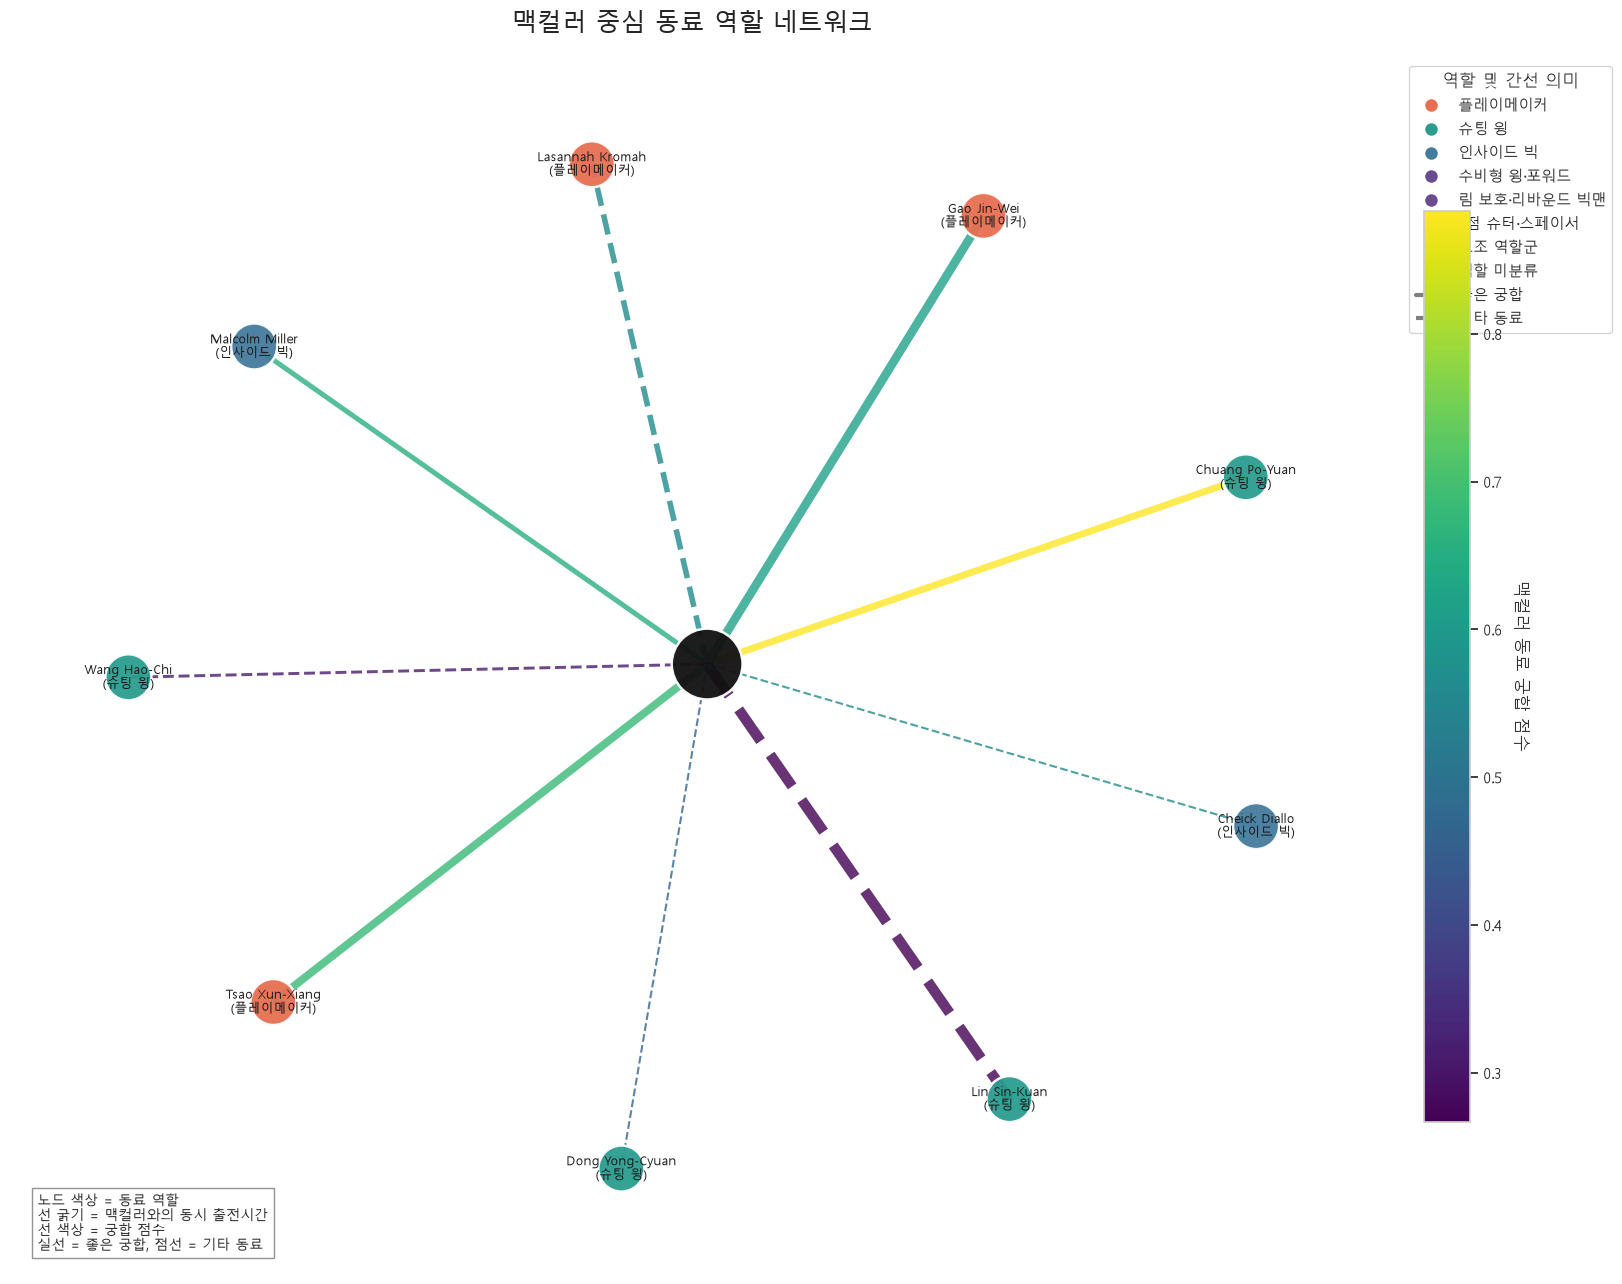

그래프 저장 완료: c:\Users\livin\OneDrive\바탕 화면\foreign_1st\mcc_role_analysis\mcc_teammate_role_network.png


In [12]:
# ============================================================
# 맥컬러 동료 역할 네트워크 시각화
# 이전 셀에서 usable 생성 후 실행
# ============================================================

import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable


# ============================================================
# 1. 데이터 확인
# ============================================================

if "usable" not in globals():
    raise NameError(
        "usable 변수가 없습니다. "
        "먼저 맥컬러 역할 분석 셀을 실행해주세요."
    )

plot_df = usable.copy()


# ============================================================
# 2. 숫자형 변환
# ============================================================

numeric_columns = [
    "sharedminutes",
    "teamwithposs",
    "teamnetvsbaseline",
    "adjustedrelativefitscore",
    "relativefitscore",
    "reliability"
]

for col in numeric_columns:
    if col in plot_df.columns:
        plot_df[col] = pd.to_numeric(
            plot_df[col],
            errors="coerce"
        )


# ============================================================
# 3. 이름·역할 기본값 처리
# ============================================================

if "name" not in plot_df.columns:
    plot_df["name"] = (
        plot_df["target"]
        .astype(str)
    )

plot_df["name"] = (
    plot_df["name"]
    .fillna(
        plot_df["target"].astype(str)
    )
    .astype(str)
)

plot_df["archetype"] = (
    plot_df["archetype"]
    .fillna("역할 미분류")
    .astype(str)
)

plot_df["sharedminutes"] = (
    plot_df["sharedminutes"]
    .fillna(0)
)

plot_df["adjustedrelativefitscore"] = (
    plot_df["adjustedrelativefitscore"]
    .fillna(0)
)

plot_df["teamnetvsbaseline"] = (
    plot_df["teamnetvsbaseline"]
    .fillna(0)
)


# ============================================================
# 4. 그래프 생성
# ============================================================

MCC_ID = "MCC"

G = nx.Graph()

# 맥컬러 중심 노드
G.add_node(
    MCC_ID,
    name="Chris McCullough",
    role="맥컬러",
    node_type="center"
)


# 역할별 색상
role_colors = {
    "플레이메이커": "#E76F51",
    "슈팅 윙": "#2A9D8F",
    "인사이드 빅": "#457B9D",
    "수비형 윙·포워드": "#6A4C93",
    "림 보호·리바운드 빅맨": "#6A4C93",
    "3점 슈터·스페이서": "#2A9D8F",
    "보조 역할군": "#A8A8A8",
    "역할 미분류": "#A8A8A8"
}


# 동료 노드와 간선 추가
for _, row in plot_df.iterrows():

    player_id = str(
        row.get(
            "target",
            row["name"]
        )
    )

    player_name = str(
        row["name"]
    )

    role = str(
        row["archetype"]
    )

    shared_minutes = float(
        row["sharedminutes"]
    )

    fit_score = float(
        row["adjustedrelativefitscore"]
    )

    team_effect = float(
        row["teamnetvsbaseline"]
    )

    good_fit = bool(
        row.get(
            "good_fit",
            False
        )
    )

    G.add_node(
        player_id,
        name=player_name,
        role=role,
        node_type="teammate",
        good_fit=good_fit
    )

    G.add_edge(
        MCC_ID,
        player_id,
        shared_minutes=shared_minutes,
        fit_score=fit_score,
        team_effect=team_effect,
        good_fit=good_fit
    )


# ============================================================
# 5. 레이아웃
# ============================================================

pos = nx.spring_layout(
    G,
    seed=42,
    k=2.2,
    iterations=300
)


# ============================================================
# 6. 노드 스타일
# ============================================================

node_list = list(G.nodes)

node_colors = []
node_sizes = []
node_labels = {}

for node in node_list:

    if node == MCC_ID:
        node_colors.append("#111111")
        node_sizes.append(2600)
        node_labels[node] = "맥컬러"

    else:
        role = G.nodes[node].get(
            "role",
            "역할 미분류"
        )

        player_name = G.nodes[node].get(
            "name",
            node
        )

        node_colors.append(
            role_colors.get(
                role,
                "#A8A8A8"
            )
        )

        node_sizes.append(1100)

        node_labels[node] = (
            f"{player_name}\n"
            f"({role})"
        )


# ============================================================
# 7. 간선 스타일
# ============================================================

edge_list = list(G.edges)

shared_minutes = np.array(
    [
        G[u][v].get(
            "shared_minutes",
            0
        )
        for u, v in edge_list
    ],
    dtype=float
)

fit_scores = np.array(
    [
        G[u][v].get(
            "fit_score",
            0
        )
        for u, v in edge_list
    ],
    dtype=float
)

# 함께 뛴 시간에 따른 선 굵기
if len(shared_minutes) > 0:
    min_minutes = shared_minutes.min()
    max_minutes = shared_minutes.max()

    if max_minutes == min_minutes:
        edge_widths = np.repeat(
            3.0,
            len(shared_minutes)
        )
    else:
        edge_widths = (
            1.5
            + 6.0
            * (
                (shared_minutes - min_minutes)
                / (max_minutes - min_minutes)
            )
        )
else:
    edge_widths = []


# 궁합 점수에 따른 선 색상
if len(fit_scores) > 0:
    fit_min = fit_scores.min()
    fit_max = fit_scores.max()

    if fit_max == fit_min:
        fit_norm = Normalize(
            vmin=0,
            vmax=1
        )
    else:
        fit_norm = Normalize(
            vmin=fit_min,
            vmax=fit_max
        )
else:
    fit_norm = Normalize(
        vmin=0,
        vmax=1
    )


edge_colors = [
    plt.cm.viridis(
        fit_norm(score)
    )
    for score in fit_scores
]


# 좋은 궁합 동료는 실선, 나머지는 점선
edge_styles = []

for u, v in edge_list:
    good_fit = G[u][v].get(
        "good_fit",
        False
    )

    if good_fit:
        edge_styles.append("solid")
    else:
        edge_styles.append("dashed")


# ============================================================
# 8. 그래프 그리기
# ============================================================

fig, ax = plt.subplots(
    figsize=(17, 13)
)

# 간선은 스타일별로 나눠 그려야 실선·점선 구분 가능
for style in ["solid", "dashed"]:

    style_edges = [
        edge
        for edge, edge_style in zip(
            edge_list,
            edge_styles
        )
        if edge_style == style
    ]

    style_indices = [
        i
        for i, edge_style in enumerate(
            edge_styles
        )
        if edge_style == style
    ]

    if len(style_edges) == 0:
        continue

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=style_edges,
        width=[
            edge_widths[i]
            for i in style_indices
        ],
        edge_color=[
            edge_colors[i]
            for i in style_indices
        ],
        style=style,
        alpha=0.80,
        ax=ax
    )


# 노드
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=node_list,
    node_color=node_colors,
    node_size=node_sizes,
    edgecolors="white",
    linewidths=1.8,
    alpha=0.95,
    ax=ax
)


# 라벨
nx.draw_networkx_labels(
    G,
    pos,
    labels=node_labels,
    font_size=9,
    font_family="Malgun Gothic",
    ax=ax
)


# ============================================================
# 9. 범례
# ============================================================

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label=role,
        markerfacecolor=color,
        markersize=10
    )
    for role, color in role_colors.items()
]

legend_handles.extend(
    [
        Line2D(
            [0],
            [0],
            color="gray",
            linewidth=3,
            linestyle="-",
            label="좋은 궁합"
        ),
        Line2D(
            [0],
            [0],
            color="gray",
            linewidth=3,
            linestyle="--",
            label="기타 동료"
        )
    ]
)

ax.legend(
    handles=legend_handles,
    title="역할 및 간선 의미",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=True
)


# ============================================================
# 10. 궁합 점수 컬러바
# ============================================================

sm = ScalarMappable(
    norm=fit_norm,
    cmap=plt.cm.viridis
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    shrink=0.75,
    pad=0.03
)

cbar.set_label(
    "맥컬러 동료 궁합 점수",
    rotation=270,
    labelpad=20
)


# ============================================================
# 11. 제목 및 저장
# ============================================================

ax.set_title(
    "맥컬러 중심 동료 역할 네트워크",
    fontsize=18,
    pad=20
)

ax.text(
    0.02,
    0.02,
    "노드 색상 = 동료 역할\n"
    "선 굵기 = 맥컬러와의 동시 출전시간\n"
    "선 색상 = 궁합 점수\n"
    "실선 = 좋은 궁합, 점선 = 기타 동료",
    transform=ax.transAxes,
    fontsize=10,
    bbox=dict(
        facecolor="white",
        alpha=0.85,
        edgecolor="gray"
    )
)

ax.axis("off")

plt.tight_layout()

output_file = os.path.join(
    OUTPUT_DIR,
    "mcc_teammate_role_network.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "그래프 저장 완료:",
    os.path.abspath(output_file)
)